# Revenue Forecasting

How the revenue forecast in US-3.2.1 was chosen, tuned and built. The notebook runs
top to bottom: it explores the dataset, defines how a forecast is scored, measures
three benchmark models, designs the model the application serves, selects its features
and hyperparameters, checks what it learned, tests that it applies to another region,
and trains and saves the artifact the API loads.

## Goal

One number per business: next month's total revenue, from that business's own sales
history.

## Constraint

The forecast is served by one model, trained once, stored, and reused for every
business. Not a model fitted per request, and not a model per customer. It also has to
apply to a business in another region without retraining, so a shop that rests on
Friday and observes Eid gets sensible answers from a model trained on a UK retailer.

This constraint rules out the classical per-series approach and drives the design in
section 5.

## Evaluation

Rolling-origin cross-validation: every month is forecast from only the data that
existed before it. Five metrics are reported, and MAPE (mean absolute percentage
error) is the one the model is selected on. Section 2 defines both and explains the
choice.

## Dataset

UCI Online Retail II: about two years of transactions from a UK-based online retailer.
Revenue per line is `quantity * unit_price`. The file is not committed. Place
`online_retail_II.xlsx` beside this notebook, or point `RETAIL_XLSX` at it.

In [1]:
%matplotlib inline
import logging
import os
import pathlib
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True  # silence Stan's per-fit chatter
logging.getLogger("prophet").setLevel(logging.WARNING)

# Make the backend package importable however the kernel was started.
for candidate in [
    pathlib.Path.cwd(),
    pathlib.Path.cwd().parent,
    pathlib.Path.cwd() / "backend",
    pathlib.Path.cwd().parent / "backend",
]:
    if (candidate / "app" / "forecast").is_dir():
        BACKEND = candidate.resolve()
        sys.path.insert(0, str(BACKEND))
        break
else:
    raise RuntimeError("Could not locate the backend directory containing app/forecast.")

print("backend:", BACKEND)

DATA_PATH = os.environ.get("RETAIL_XLSX") or str(BACKEND / "notebooks" / "online_retail_II.xlsx")
if not pathlib.Path(DATA_PATH).exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Put online_retail_II.xlsx beside this "
        "notebook, or set RETAIL_XLSX to its path."
    )
print("dataset:", DATA_PATH)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

backend: /Users/maen/ASAL-AI26/Project B/backend
dataset: /Users/maen/ASAL-AI26/Project B/backend/notebooks/online_retail_II.xlsx


The series construction, monthly rollup, backtest, models and holiday calendar are
imported from `app.forecast` rather than reimplemented here, so every number below is
produced by the code that runs in production.

In [2]:
from app.forecast.daily_series import DailyRevenueSeries, build_daily_revenue_series
from app.forecast.evaluation import (
    COLD_START_MONTHS,
    MIN_HISTORY_MONTHS,
    expanding_backtest,
    mape_by_history,
)
from app.forecast.holiday_calendar import holiday_calendar
from app.forecast.monthly import monthly_totals
from app.forecast.simple_models import linear_trend_forecast, moving_average_forecast
from app.forecast.trained_revenue_model import (
    BASELINE_WINDOW,
    DEFAULT_PARAMS,
    FEATURE_NAMES,
    TrainedRevenueModel,
    build_features,
    detect_closed_days,
)

print("cold start is under", COLD_START_MONTHS, "months of history")
print("a forecast needs at least", MIN_HISTORY_MONTHS, "complete months")
print("the scale baseline is the trailing", BASELINE_WINDOW, "days")

cold start is under 12 months of history
a forecast needs at least 3 complete months
the scale baseline is the trailing 28 days


---
# 1. The data

What the sales file contains, and which patterns are strong enough to model.

In [3]:
xl = pd.ExcelFile(DATA_PATH)
raw = pd.concat([pd.read_excel(xl, sheet_name=s) for s in xl.sheet_names], ignore_index=True)
print("sheets:", xl.sheet_names)
print("rows:", f"{len(raw):,}")
raw.head()

sheets: ['Year 2009-2010', 'Year 2010-2011']
rows: 1,067,371


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
print("Date range:", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())
print(
    "Products:",
    raw["StockCode"].nunique(),
    "| Customers:",
    raw["Customer ID"].nunique(),
    "| Countries:",
    raw["Country"].nunique(),
)
print("Cancellations (invoice starts with C):", int(raw["Invoice"].astype(str).str.startswith("C").sum()))
print("Negative-quantity rows (returns):", int((raw["Quantity"] < 0).sum()))
print("Zero or negative price rows:", int((raw["Price"] <= 0).sum()))
print("\nMissing values per column:")
print(raw.isna().sum())

Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Products: 5305 | Customers: 5942 | Countries: 43
Cancellations (invoice starts with C): 19494
Negative-quantity rows (returns): 22950
Zero or negative price rows: 6207

Missing values per column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


### From line items to a daily revenue series

Exact duplicate rows are dropped first, matching the cleaning step in the upload
pipeline. Deduplicating on the whole row removes re-recorded line items without
collapsing genuinely repeated sales of the same product.

A day inside the trading range with no transactions is recorded as zero, not as
missing. A closed day is information: it is what lets the model learn a rest day and a
holiday shutdown. Interpolating those days away would remove the strongest signal in
the data.

Returns are kept and net against the day's total, since a return is real lost revenue.

In [5]:
std = raw.drop_duplicates().rename(
    columns={
        "InvoiceDate": "transaction_date",
        "Quantity": "quantity",
        "Price": "unit_price",
        "StockCode": "product_id",
        "Description": "product_name",
    }
)
print(f"rows before dedup: {len(raw):,}   after: {len(std):,}   removed: {len(raw) - len(std):,}")

daily = build_daily_revenue_series(std)
series = daily.series
monthly = monthly_totals(series)

print(daily.summary())
print("Complete months:", len(monthly), f"({monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m})")

rows before dedup: 1,067,371   after: 1,033,036   removed: 34,335
Daily series: 739 days (2009-12-01 to 2011-12-09), 604 with sales, 135 filled as zero.
Complete months: 24 (2009-12 to 2011-11)


`monthly_totals` drops a partial month at either end. The file starts on 1 December
2009 and stops on 9 December 2011, so the trailing part-month of December 2011 is
excluded. Keeping it would show a drop in revenue that is only a truncated month, and
would distort any trend fitted through the series.

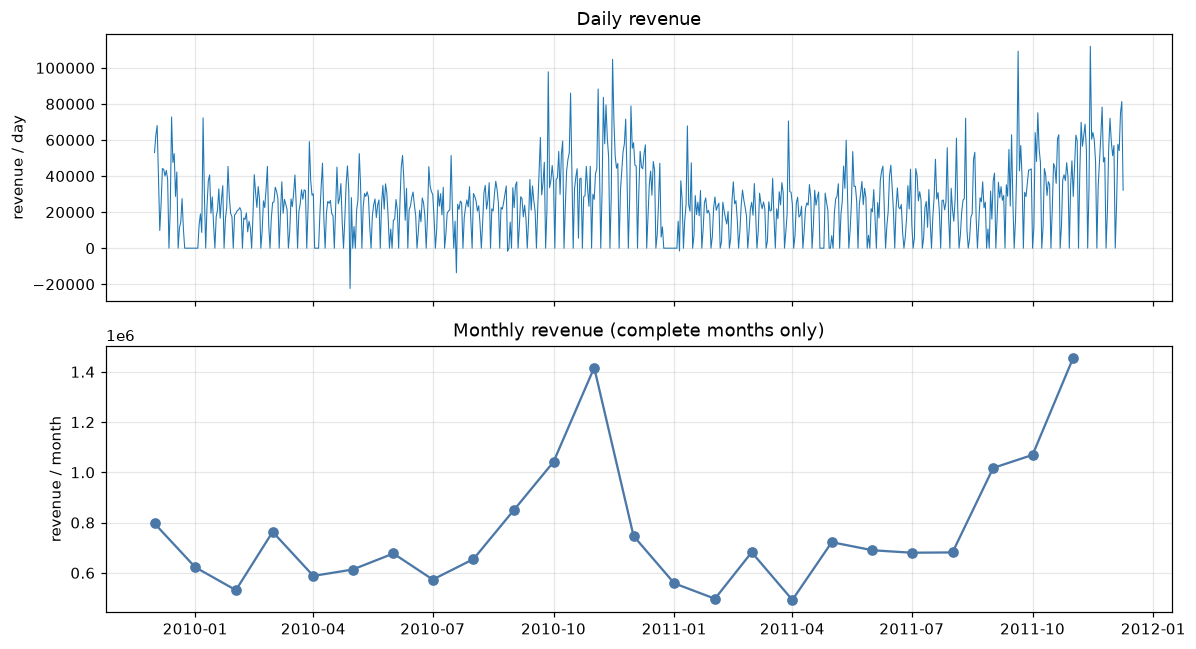

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(series.index, series.values, lw=0.7)
ax[0].set_title("Daily revenue")
ax[0].set_ylabel("revenue / day")
ax[1].plot(monthly.index, monthly.values, "-o", color="#4C78A8")
ax[1].set_title("Monthly revenue (complete months only)")
ax[1].set_ylabel("revenue / month")
plt.tight_layout()
plt.show()

### Weekly, yearly and holiday patterns

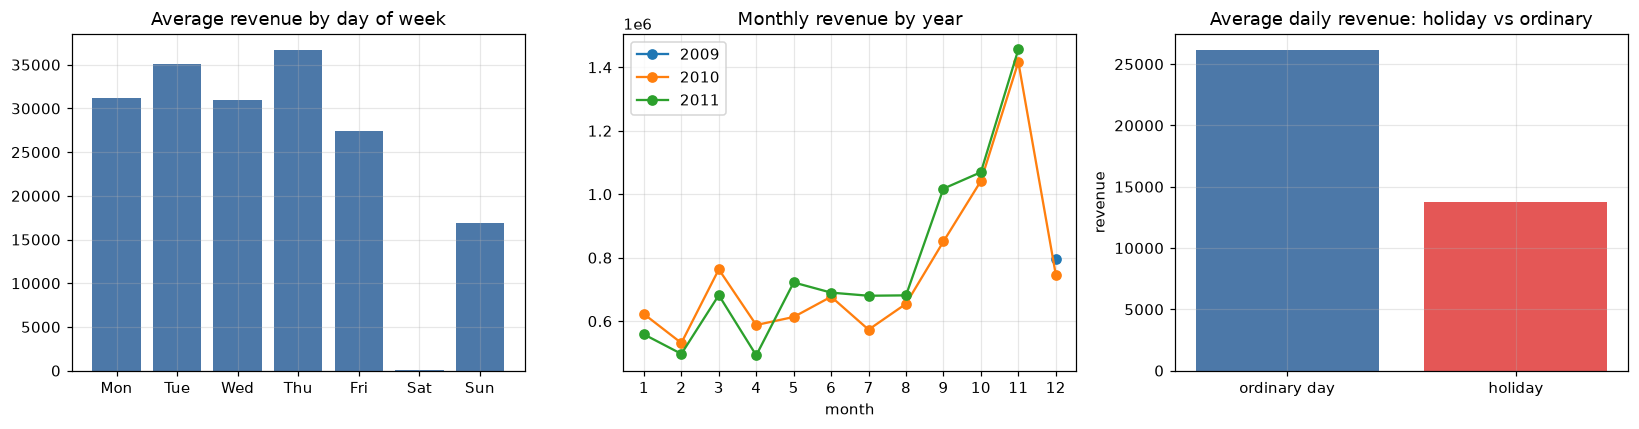

Weekdays detected as closed: {5} -> ['Sat']
Holiday days average 53% of an ordinary day.


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# (a) Weekly cycle.
dow = series.groupby(series.index.dayofweek).mean().reindex(range(7))
ax[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values, color="#4C78A8")
ax[0].set_title("Average revenue by day of week")

# (b) Yearly cycle, one line per year on a shared month axis.
for year in sorted(set(monthly.index.year)):
    year_months = monthly[monthly.index.year == year]
    ax[1].plot(year_months.index.month, year_months.values, "-o", label=str(year))
ax[1].set_title("Monthly revenue by year")
ax[1].set_xlabel("month")
ax[1].set_xticks(range(1, 13))
ax[1].legend()

# (c) Holiday effect, using the region calendar the application ships.
years = list(range(int(series.index.year.min()), int(series.index.year.max()) + 1))
holiday_dates = set(pd.to_datetime(holiday_calendar("europe", years)["ds"]).dt.normalize())
is_holiday = series.index.normalize().isin(holiday_dates)
ax[2].bar(
    ["ordinary day", "holiday"], [series[~is_holiday].mean(), series[is_holiday].mean()], color=["#4C78A8", "#E45756"]
)
ax[2].set_title("Average daily revenue: holiday vs ordinary")
ax[2].set_ylabel("revenue")

plt.tight_layout()
plt.show()

closed = detect_closed_days(series)
print(
    "Weekdays detected as closed:",
    closed,
    "->",
    [["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][d] for d in sorted(closed)],
)
print(f"Holiday days average {series[is_holiday].mean() / series[~is_holiday].mean():.0%} of an ordinary day.")

All three patterns are present:

- Weekly: Saturday is near zero. `detect_closed_days` finds it from the data without
  being told which day the weekend falls on.
- Yearly: both years rise steeply into November and December, so the shape repeats.
- Holiday: a public holiday averages roughly half an ordinary day.

A model that ignores any of these will be wrong in the months where the error costs
most.

In [8]:
line_revenue = std["quantity"] * std["unit_price"]
print("Line revenue percentiles:")
print(line_revenue.describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print(
    "\nNegative-revenue days:",
    int((series < 0).sum()),
    "| max day:",
    f"{series.max():,.0f}",
    "| 99th pct:",
    f"{series.quantile(0.99):,.0f}",
    "| median:",
    f"{series.median():,.0f}",
)

# Real products carry a 5-digit stock code; anything else is a bookkeeping line
# (postage, fees, discounts, adjustments, gift vouchers, tests).
codes = std["product_id"].astype(str).str.upper()
non_product = ~codes.str.match(r"^\d{5}")
print(
    "\nNon-product (administrative) rows:",
    f"{int(non_product.sum()):,}",
    "-> net revenue:",
    f"{line_revenue[non_product].sum():,.0f}",
)
print("\nLargest single-day totals:")
print(series.sort_values(ascending=False).head().round(0))

Line revenue percentiles:
count    1033036.00
mean          18.25
std          295.69
min      -168469.60
50%            9.92
90%           32.96
99%          182.88
max       168469.60
dtype: float64

Negative-revenue days: 4 | max day: 111,959 | 99th pct: 80,601 | median: 24,422

Non-product (administrative) rows: 5,980 -> net revenue: -70,732

Largest single-day totals:
date
2011-11-14    111959.0
2011-09-20    109228.0
2010-11-15    104709.0
2010-09-27     97805.0
2010-11-04     88268.0
dtype: float64


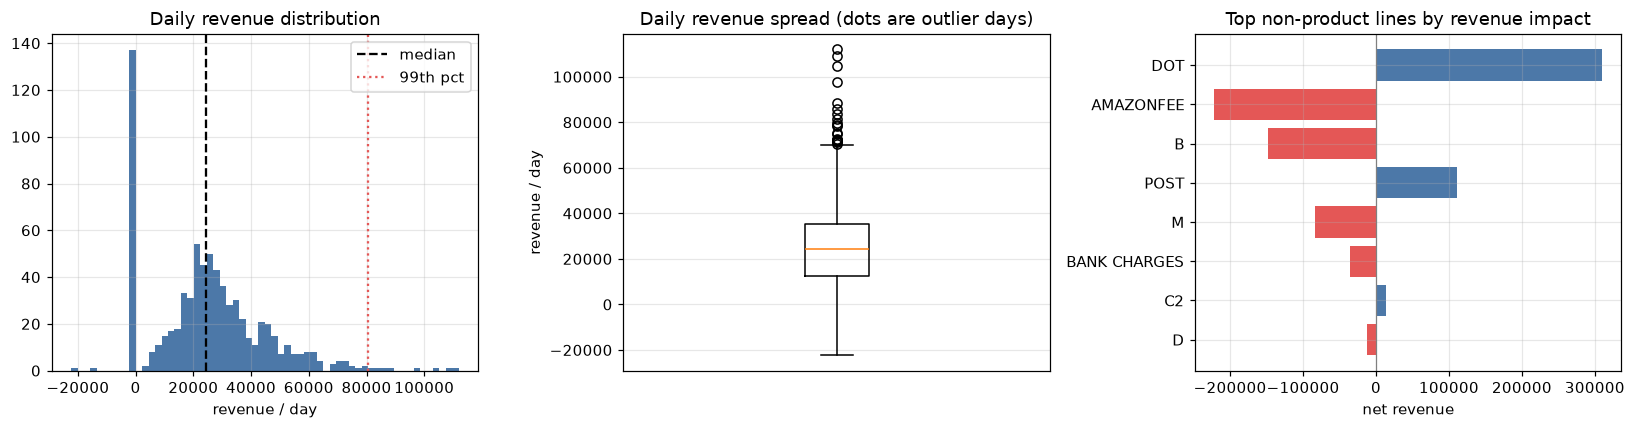

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(series.values, bins=60, color="#4C78A8")
ax[0].axvline(series.median(), color="k", ls="--", label="median")
ax[0].axvline(series.quantile(0.99), color="#E45756", ls=":", label="99th pct")
ax[0].set_title("Daily revenue distribution")
ax[0].set_xlabel("revenue / day")
ax[0].legend()

ax[1].boxplot(series.values, showfliers=True)
ax[1].set_title("Daily revenue spread (dots are outlier days)")
ax[1].set_ylabel("revenue / day")
ax[1].set_xticks([])

impact = line_revenue[non_product].groupby(codes[non_product]).sum()
impact = impact.reindex(impact.abs().sort_values(ascending=False).index).head(8)[::-1]
ax[2].barh(impact.index, impact.values, color=["#E45756" if v < 0 else "#4C78A8" for v in impact.values])
ax[2].axvline(0, color="grey", lw=0.8)
ax[2].set_title("Top non-product lines by revenue impact")
ax[2].set_xlabel("net revenue")

plt.tight_layout()
plt.show()

### What carries forward

- Saturday is the rest day, revenue climbs into Christmas, and holidays depress a day.
  These are the effects to model.
- There are a few very large single-day spikes and a set of administrative rows
  (postage, fees, adjustments). Both are left in. The target is a monthly total, and
  summing a month dilutes a single spike. Stripping the administrative codes would
  matter for a per-product forecast; it is a cleaning candidate if that is built.
- Returns are netted rather than removed, so the forecast predicts money actually
  taken.

---
# 2. Cross-validation and metrics

Comparing models needs one measurement, fixed before any model is chosen.

## 2.1 The cross-validation scheme

This is **rolling-origin cross-validation** with an expanding window, the standard
form of cross-validation for time series. Ordinary k-fold is not valid here: shuffling
months into random folds would train on data that comes after the month being
predicted, so the score would include information the model cannot have at serving
time and would be optimistic.

Instead the origin rolls forward. For every month from the fourth onward, the model is
refitted on only the data that existed before that month, asked for that month's total,
and compared against the actual. Each month is a fold, 21 folds in total, and no fold
ever sees its own future. This is also the exact situation the deployed endpoint is in:
history up to now, forecast the next month.

Results are split by history length, because a single average hides what matters most
for this product. Most SME users upload months rather than years:

- cold start: forecasts made with under a year of history
- rich history: forecasts made with a year or more

A model that is accurate only after two years is not usable here. Neither is one that
starts well and degrades.

The implementation is `app.forecast.evaluation`, which the training script also uses.

## 2.2 Which metric, and why

Five metrics are reported on every model. Only one of them selects the model.

| Metric | What it measures | Used for selection |
| ------ | ---------------- | ------------------ |
| **MAPE** | mean absolute percentage error, `abs(predicted - actual) / actual` | **yes** |
| MAE | mean absolute error, in currency | no |
| RMSE | root mean squared error, in currency | no |
| R² | share of the variance in monthly revenue the forecast explains | no |
| MASE | MAE relative to the naive "next month equals last month" rule | no |

**MAPE selects the model.** It is scale-free, so it means the same thing for a shop
taking £200 a day and one taking £20,000, which is a requirement when one model serves
every business and its accuracy has to be stated once for all of them. It is also the
number a business owner can read directly: "the forecast is typically within 16%".

Its known weaknesses are worth stating. MAPE is undefined when the actual is zero and
unstable when the actual is near zero, which is why `rolling_origin_cv` returns `nan`
for a zero-revenue month and excludes it from the mean rather than letting it dominate.
MAPE is also asymmetric: it penalises over-forecasting more than under-forecasting of
the same absolute size. Neither weakness bites on monthly totals for a trading
business, where the actual is far from zero.

**MAE and RMSE are in pounds**, so they cannot be averaged across businesses of
different sizes and cannot support a single accuracy claim for the product. They are
reported because they are what a single business would care about, and because RMSE
exposes whether the error is a few large misses or many small ones.

**R² answers a different question**: how much of the month-to-month variation in
revenue the forecast captures, against a reference of always predicting the mean of the
evaluation period. It is reported because it is the standard summary for a regression
and a reviewer will look for it, but it is not used for selection, for two reasons. The
reference it scores against is the mean of the months being predicted, which is a
quantity the forecaster never had access to, so it flatters or punishes a model for
reasons unrelated to forecasting. And it is not scale-free across businesses, so it
cannot become the product's accuracy claim. It is a useful sanity check in one
direction: a negative R² means the model is worse than a flat line through the test
period, which is a genuine failure.

**MASE is the honest cross-series metric.** It divides the model's MAE by the MAE of
the naive "next month equals last month" rule on the same folds, so 1.0 means no better
than doing nothing and below 1.0 means real skill. It is scale-free and stays defined
when the actual is zero, which makes it the metric to move to once the model trains
across many businesses at once. It is not used for selection here because with a single
series its denominator is one business's naive error, so it carries no more information
than MAE does.

In [10]:
def as_series_object(s):
    """Wrap a bare daily series in the DailyRevenueSeries the simple models take."""
    return DailyRevenueSeries(s, s.index[0], s.index[-1], len(s), int((s != 0).sum()), 0)


def score(predict, **kwargs):
    """Expanding-backtest a forecaster and return (folds, cold, rich, overall)."""
    folds = expanding_backtest(series, predict, **kwargs)
    cold, rich, overall = mape_by_history(folds)
    return folds, cold, rich, overall


demo, cold, rich, overall = score(lambda history: float(monthly_totals(history).iloc[-1]))
print("Worked example: 'next month equals last month'")
print(demo.round(1).head())
print(f"\n{len(demo)} forecasts, from {demo.nmonths.min()} to {demo.nmonths.max()} months of history")
print(f"cold start {cold:.1f}%   rich history {rich:.1f}%   overall {overall:.1f}%")

Worked example: 'next month equals last month'
              actual  predicted   ape  nmonths
2010-03-01  763247.2   531265.4  30.4        3
2010-04-01  587926.7   763247.2  29.8        4
2010-05-01  613270.7   587926.7   4.1        5
2010-06-01  677073.9   613270.7   9.4        6
2010-07-01  573333.7   677073.9  18.1        7

21 forecasts, from 3 to 23 months of history
cold start 19.1%   rich history 25.3%   overall 22.7%


That naive rule is the floor every real model has to clear, and it is also the
denominator of MASE, so it is computed once here and reused.

In [11]:
NAIVE_MAE = float((demo["predicted"] - demo["actual"]).abs().mean())


def metrics(folds):
    """All five metrics for one model's cross-validation folds."""
    error = folds["predicted"] - folds["actual"]
    actual = folds["actual"]
    ss_res = float((error**2).sum())
    ss_tot = float(((actual - actual.mean()) ** 2).sum())
    return {
        "MAPE %": folds["ape"].mean(),
        "MAE": error.abs().mean(),
        "RMSE": float(np.sqrt((error**2).mean())),
        "R2": 1 - ss_res / ss_tot,
        "MASE": error.abs().mean() / NAIVE_MAE,
    }


print(
    f"Monthly revenue over the {len(demo)} evaluated months: "
    f"mean {demo['actual'].mean():,.0f}, standard deviation {demo['actual'].std():,.0f}"
)
print("\nThe naive rule scored on every metric:")
for name, value in metrics(demo).items():
    print(f"  {name:8} {value:>12,.3f}")

Monthly revenue over the 21 evaluated months: mean 784,401, standard deviation 270,516

The naive rule scored on every metric:
  MAPE %         22.672
  MAE       180,262.380
  RMSE      239,010.857
  R2              0.180
  MASE            1.000


MASE is 1.0 for the naive rule by construction, since it is its own denominator. Its
R² of 0.18 is the reference the other models have to beat: a model scoring below that
explains less of the variation in monthly revenue than simply carrying last month
forward.

---
# 3. Benchmarks 1 and 2: the simple models

Two models that need no training. Both work on monthly totals.

- Moving average: next month is the mean of the last three months.
- Linear trend: fit a least-squares line through the monthly totals and extend it one
  month.

They are cheap and explainable, which makes them the bar to clear.

In [12]:
results = {}

results["moving average"] = score(lambda history: moving_average_forecast(as_series_object(history)).predicted_revenue)
results["linear trend"] = score(lambda history: linear_trend_forecast(as_series_object(history)).predicted_revenue)

for name in ["moving average", "linear trend"]:
    _, c, r, o = results[name]
    print(f"{name:16} cold {c:5.1f}%   rich {r:5.1f}%   overall {o:5.1f}%")

moving average   cold  15.8%   rich  32.2%   overall  25.2%
linear trend     cold  22.3%   rich  33.3%   overall  28.6%


Both are reasonable early and get worse as history grows. Their error is dominated by
the Christmas peak, and neither has a way to anticipate it however many years it has
seen. The moving average is accurate in a flat stretch and badly wrong in November.

---
# 4. Benchmark 3: daily Prophet

Prophet decomposes a daily series into trend, weekly seasonality, yearly seasonality
and holiday effects, which is the structure section 1 found. It is fitted on the daily
series with the region's holiday calendar, and the forecast days are summed into a
monthly total.

It is a benchmark rather than a candidate because it fits one model to one series.
There is nothing to train once and share: every request refits from scratch, and a
business in its first months has no yearly cycle to fit.

In [13]:
from app.forecast.prophet_model import daily_prophet_forecast


def prophet_predict(history):
    try:
        return daily_prophet_forecast(as_series_object(history), region="europe").predicted_revenue
    except Exception:
        return float("nan")


results["daily Prophet"] = score(prophet_predict)
_, c, r, o = results["daily Prophet"]
print(f"{'daily Prophet':16} cold {c:5.1f}%   rich {r:5.1f}%   overall {o:5.1f}%")

daily Prophet    cold  72.1%   rich  11.3%   overall  37.4%


Prophet is the most accurate model in this notebook once a business has a full year,
and the least accurate before that, because it is fitting a yearly seasonality from
less than a year of data. For a product whose users are mostly new businesses, that
rules it out independently of the deployment constraint.

On reproducing this row: Prophet fits through Stan, whose optimiser lands on slightly
different parameters across platforms and versions, so its cold-start figure moves by a
few points on a re-run elsewhere. The gap between the two regimes is stable. The other
three models are deterministic and reproduce exactly.

---
# 5. Designing a model that can be trained once and shared

The constraint again: one artifact, trained once, serving every business, and
applicable in another region without retraining.

A model trained on this retailer's revenue in pounds would learn that a normal day is
about £2,000. Served to a shop taking £200 a day, every number is ten times too large.
Served to a shop that closes Friday, it predicts a normal Friday and a dead Saturday.
Three changes fix that.

### 5.1 Predict a ratio, not an amount

The target is revenue divided by the trailing 28-day average. The model learns that a
rest day is about 0x normal, that the day before a holiday runs high, that week 48 runs
above normal. Those statements hold for a corner shop and a warehouse alike. Converting
back is exact: multiply the predicted ratio by that business's own baseline.

28 days is four whole weekly cycles, so the baseline does not shift with the day of the
week it happens to end on.

### 5.2 Read the rest day out of the data

`detect_closed_days` marks any weekday whose revenue is zero on at least 80% of
occurrences. Section 1 showed it finding Saturday here. Pointed at a business that
rests on Friday it returns Friday, and the learned "closed day is about 0x" applies
unchanged. This is the feature that makes a UK-trained model safe to run in the Middle
East.

### 5.3 Describe holidays generically

The holiday features are `is_holiday`, `is_holiday_eve`, `is_after_holiday`,
`days_to_holiday` and `days_from_holiday`. None of them names a holiday. They describe
the shape of behaviour around one: the run-up, the day itself, the recovery. The
columns are identical in every market and only the dates change, which is what the
region calendar supplies. A ramp learned on Christmas is available to Eid.

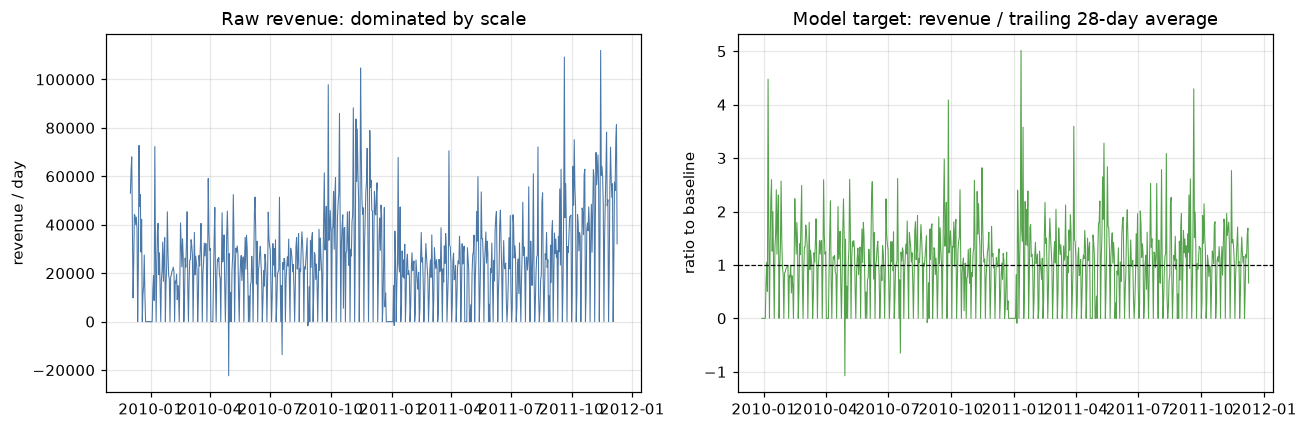

Target ratio: median 1.09, mean 1.04, 5th-95th pct 0.00-2.24

The features the shipped model sees:
  - month
  - day
  - weekofyear
  - is_closed_day
  - weekday_ratio
  - is_holiday
  - is_holiday_eve
  - is_after_holiday
  - days_to_holiday
  - days_from_holiday
  - lag364_ratio


In [14]:
baseline_full = series.shift(1).rolling(BASELINE_WINDOW).mean()
target_ratio = series / baseline_full
target_ratio = target_ratio[np.isfinite(target_ratio) & (baseline_full > 0)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(series.index, series.values, lw=0.7, color="#4C78A8")
ax[0].set_title("Raw revenue: dominated by scale")
ax[0].set_ylabel("revenue / day")
ax[1].plot(target_ratio.index, target_ratio.values, lw=0.7, color="#54A24B")
ax[1].axhline(1.0, color="k", ls="--", lw=0.8)
ax[1].set_title(f"Model target: revenue / trailing {BASELINE_WINDOW}-day average")
ax[1].set_ylabel("ratio to baseline")
plt.tight_layout()
plt.show()

print(
    "Target ratio:",
    f"median {target_ratio.median():.2f},",
    f"mean {target_ratio.mean():.2f},",
    f"5th-95th pct {target_ratio.quantile(0.05):.2f}-{target_ratio.quantile(0.95):.2f}",
)
print("\nThe features the shipped model sees:")
for name in FEATURE_NAMES:
    print("  -", name)

The right-hand series is what the model predicts. It sits around 1.0 with structure on
top and carries no information about how large this business is, which is what lets one
model serve all of them.

That printed list is the outcome of the next section, not an assumption going into it.
Section 5.4 scores every combination of the candidates and arrives at exactly this set,
and it checks the result against `FEATURE_NAMES` on every run.

## 5.4 Which features earn their place

Sections 5.1 to 5.3 fix what the model is allowed to look at. They do not settle which
of those signals is worth keeping, and that is a question to measure rather than assume.

A base set is always present, because it is what the scale-free target and the region
calendar give for free: `month`, `day`, `weekofyear`, the detected rest-day flag, the
five holiday columns, and last year's same-weekday value as a ratio. Four further
groups are candidates, every one of them region-transferable:

- `weekday_ratio`: each weekday's own average ratio to the baseline, read from this
  store's history. The graded form of the rest-day flag: a closed day lands near 0, a
  quiet weekday below 1, the busiest weekday above 1.
- rest-day neighbours, `is_before_closed` and `is_after_closed`: the days either side of
  a closure, where trade is often pulled forward or pushed back.
- `momentum`: the last 7 days relative to the 28-day baseline, giving recent direction.
- cyclical, `doy_sin`, `doy_cos` and `month_progress`: smooth seasonal encodings.

Every combination of the four is scored, sixteen in all, on the same expanding backtest.

### Reading a table this close

The leading sets come out within a couple of tenths of a percentage point of each other,
and that is small enough to be worth checking against the model's own noise. LightGBM
samples columns at each tree, so re-fitting the same configuration with a different
random seed moves its score by roughly that much on its own. Ranking on a single fit
would be ranking on the seed.

So every feature set is re-run across ten seeds, and the selection rule is stated
before the table is read:

1. **MAPE decides**, as section 2.2 sets out.
2. Sets whose mean MAPE falls **within twice the largest seed drift** of the best are
   treated as tied with it, because the measurement cannot separate them.
3. Among those, **R2 breaks the tie** — it is reported anyway and its seed drift is an
   order of magnitude smaller, so it can resolve what MAPE cannot.
4. If R2 ties too, the **smaller feature set wins**. Every extra column is another thing
   to compute at serving time and another way to overfit one retailer.

This does not promote R2 to a selection metric. It decides only among candidates that
MAPE has been shown unable to tell apart.

In [15]:
import itertools

import lightgbm as lgb

MOMENTUM_WINDOW = 7
COUNTRY = "GB"  # the dataset is a UK retailer

GROUPS = {
    "weekday_ratio": ["weekday_ratio"],
    "rest-day neighbours": ["is_before_closed", "is_after_closed"],
    "momentum": ["momentum"],
    "cyclical": ["doy_sin", "doy_cos", "month_progress"],
}
FROM_PRODUCTION = {"weekday_ratio"}  # build_features already emits this candidate


def candidate_columns(dates, history, baseline, closed_days, wanted):
    """Build the candidate columns `build_features` does not already produce.
    `baseline` is a scalar at a forecast origin and one value per date when training."""
    dow = dates.dayofweek
    doy = dates.dayofyear.to_numpy()
    data = {
        "is_before_closed": ((dow + 1) % 7).isin(closed_days).astype(int),
        "is_after_closed": ((dow - 1) % 7).isin(closed_days).astype(int),
        "doy_sin": np.sin(2 * np.pi * doy / 365.25),
        "doy_cos": np.cos(2 * np.pi * doy / 365.25),
        "month_progress": dates.day / dates.days_in_month,
    }
    if "momentum" in wanted:
        if np.isscalar(baseline):
            data["momentum"] = float(history.iloc[-MOMENTUM_WINDOW:].mean() / history.iloc[-BASELINE_WINDOW:].mean())
        else:
            recent = history.shift(1).rolling(MOMENTUM_WINDOW).mean()
            window = history.shift(1).rolling(BASELINE_WINDOW).mean()
            data["momentum"] = (recent / window).reindex(dates).to_numpy()
    return pd.DataFrame(data, index=dates)[wanted]


def feature_frame(dates, history, baseline, closed_days, extra):
    """The base set plus `extra`. Candidates that production already emits are taken
    from `build_features` itself, so the search scores the shipped implementation."""
    frame = build_features(dates, history, baseline, COUNTRY, closed_days)
    frame = frame.drop(columns=[c for c in FROM_PRODUCTION if c not in extra])
    computed = [c for c in extra if c not in frame.columns]
    if computed:
        frame = pd.concat([frame, candidate_columns(dates, history, baseline, closed_days, computed)], axis=1)
    return frame


def forecast_with(history, extra, seed):
    """Fit on `history` with the base set plus `extra`, forecast the next month."""
    closed_days = detect_closed_days(history)
    baseline = history.shift(1).rolling(BASELINE_WINDOW).mean().to_numpy()
    X = feature_frame(history.index, history, baseline, closed_days, extra)
    y = history.to_numpy() / baseline
    usable = np.isfinite(baseline) & (baseline > 0) & np.isfinite(y)
    model = lgb.LGBMRegressor(**{**DEFAULT_PARAMS, "random_state": seed})
    model.fit(X[usable], y[usable])

    scale = float(history.iloc[-BASELINE_WINDOW:].mean())
    start = (history.index.max() + pd.offsets.MonthBegin(1)).normalize()
    days = pd.date_range(start, start + pd.offsets.MonthEnd(0), freq="D")
    future = feature_frame(days, history, scale, closed_days, extra)
    return float((np.clip(model.predict(future), 0, None) * scale).sum())

In [16]:
SEEDS = range(10)

search_rows = []
for size in range(len(GROUPS) + 1):
    for combo in itertools.combinations(GROUPS, size):
        extra = [column for group in combo for column in GROUPS[group]]
        seed_cold, seed_rich, seed_mape, seed_r2 = [], [], [], []
        for seed in SEEDS:
            folds, cold, rich, overall = score(lambda h, e=extra, s=seed: forecast_with(h, e, s))
            seed_cold.append(cold)
            seed_rich.append(rich)
            seed_mape.append(overall)
            seed_r2.append(metrics(folds)["R2"])
        search_rows.append(
            {
                **{group: "yes" if group in combo else "" for group in GROUPS},
                "groups": combo,
                "label": " + ".join(combo) if combo else "base only",
                "cols": len(extra),
                "cold": round(float(np.mean(seed_cold)), 2),
                "rich": round(float(np.mean(seed_rich)), 2),
                "MAPE": round(float(np.mean(seed_mape)), 2),
                "sd": round(float(np.std(seed_mape, ddof=1)), 3),
                "R2": round(float(np.mean(seed_r2)), 3),
                "R2 sd": round(float(np.std(seed_r2, ddof=1)), 3),
            }
        )

search = pd.DataFrame(search_rows).sort_values("MAPE").reset_index(drop=True)
print(f"{len(search)} feature sets on top of the base set, each re-run over {len(list(SEEDS))} seeds.")
print("cold/rich/MAPE are mean MAPE %; sd is the MAPE spread across seeds.\n")
search.drop(columns=["groups", "label"])

16 feature sets on top of the base set, each re-run over 10 seeds.
cold/rich/MAPE are mean MAPE %; sd is the MAPE spread across seeds.



,weekday_ratio,rest-day neighbours,momentum,cyclical,cols,cold,rich,MAPE,sd,R2,R2 sd
0,yes,,,,1,16.45,15.88,16.12,0.131,0.695,0.004
1,,yes,,,2,16.99,15.52,16.15,0.144,0.689,0.004
2,yes,yes,,,3,16.45,15.99,16.19,0.160,0.694,0.005
3,yes,,yes,,2,19.93,14.03,16.56,0.219,0.573,0.007
4,yes,yes,yes,,4,19.99,14.00,16.57,0.171,0.571,0.006
5,,,,,0,17.04,16.56,16.77,0.137,0.685,0.004
6,,,yes,,1,22.55,15.43,18.48,0.226,0.561,0.008
7,,yes,yes,,3,22.63,16.01,18.85,0.243,0.520,0.009
8,,,,yes,3,30.01,16.61,22.36,0.126,0.148,0.009
9,,yes,,yes,5,29.96,18.12,23.19,0.130,0.117,0.013


In [17]:
drift = float(search["sd"].max())
floor = float(search["MAPE"].min())
tied = search[search["MAPE"] <= floor + 2 * drift]
r2_drift = float(tied["R2 sd"].max())
top_r2 = float(tied["R2"].max())
level = tied[tied["R2"] >= top_r2 - r2_drift]
chosen = level.nsmallest(1, "cols").iloc[0]

selected = sorted(column for group in chosen["groups"] for column in GROUPS[group])
shipped = sorted(c for columns in GROUPS.values() for c in columns if c in FEATURE_NAMES)

print(f"largest seed drift: {drift:.3f} MAPE points")
print(f"best mean MAPE: {floor:.2f}  ->  tied band: MAPE <= {floor + 2 * drift:.2f}")
print(f"{len(tied)} of {len(search)} feature sets are inside the band")
print(f"best R2 among them {top_r2:.3f}, level within its own drift of {r2_drift:.3f}: {len(level)} set(s)")
print(f"smallest of those: {chosen['label']} ({int(chosen['cols'])} extra columns)\n")
print("selected columns: ", selected)
print("in FEATURE_NAMES: ", shipped)
print("\nmatch:", selected == shipped)

largest seed drift: 0.243 MAPE points
best mean MAPE: 16.12  ->  tied band: MAPE <= 16.61
5 of 16 feature sets are inside the band
best R2 among them 0.695, level within its own drift of 0.007: 3 set(s)
smallest of those: weekday_ratio (1 extra columns)

selected columns:  ['weekday_ratio']
in FEATURE_NAMES:  ['weekday_ratio']

match: True


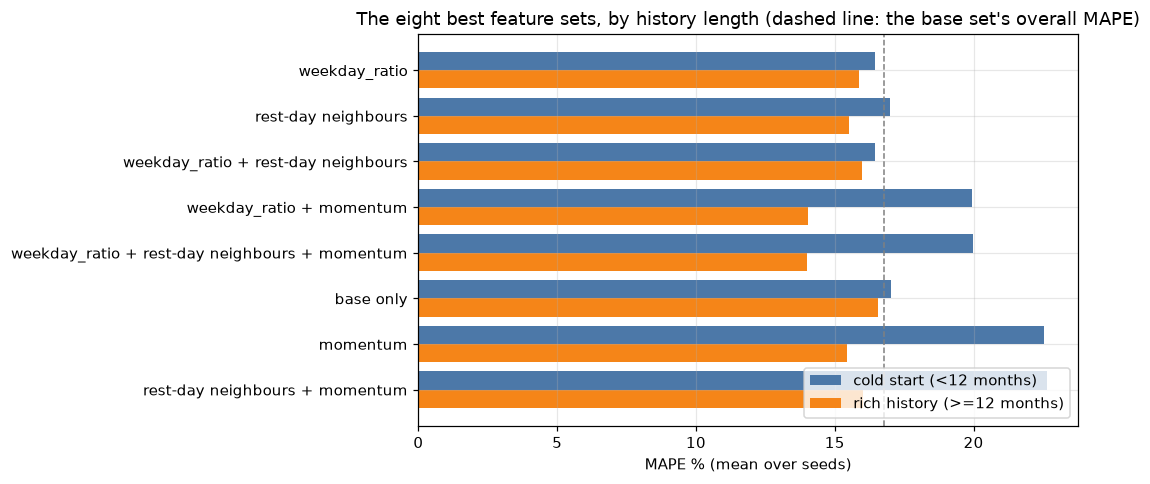

In [18]:
top = search.head(8).iloc[::-1]
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(y + 0.2, top["cold"], 0.4, label="cold start (<12 months)", color="#4C78A8")
ax.barh(y - 0.2, top["rich"], 0.4, label="rich history (>=12 months)", color="#F58518")
ax.axvline(float(search.loc[search["cols"] == 0, "MAPE"].iloc[0]), color="grey", ls="--", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(top["label"])
ax.set_xlabel("MAPE % (mean over seeds)")
ax.set_title("The eight best feature sets, by history length (dashed line: the base set's overall MAPE)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

`weekday_ratio` on its own wins, and the rest of the table says why the others do not.

It is the only candidate that improves **both** regimes: cold start from 17.0 to 16.5
and rich history from 16.6 to 15.9. A new business has enough trading days to give a
rough weekday profile within weeks, and a mature one gives a sharp one, so it pays at
both ends.

The rest-day neighbours reach a better rich-history figure than it does, 15.5, but leave
cold start exactly where the base set had it. Two binary columns marking the days either
side of a closure have little to say until a store has traded through enough of them.

Momentum is the sharpest instrument here on a mature business and the bluntest on a new
one. Paired with `weekday_ratio` it takes rich history to 14.0, the best figure anywhere
in the table, while pushing cold start from 17.0 to 19.9. That is exactly what recent
direction should do: a real signal when there is enough history to separate a trend from
a noisy fortnight, and misleading when a noisy fortnight is most of what exists. This
product's users are mostly in their first year, so the trade is the wrong way round —
but if that ever stops being true, this row is where to look first.

The cyclical encodings are worse than the base set in both regimes and take R2 from
0.685 down to 0.148. The base set already carries `weekofyear` and `month`, and a smooth
sinusoid through the year cannot represent a peak that arrives in its last six weeks: it
spreads the Christmas rise across the whole autumn and flattens it.

Five sets land inside the tied band, and R2 splits them into two groups. The three built
from `weekday_ratio` and the neighbours sit level at the top, inside R2's own seed drift
of one another. The two that include momentum are far behind at about 0.57 — the cold
start damage showing up in a metric that averages over every fold rather than splitting
them. Among the three that are level, rule 4 takes the smallest. One extra column.

One property of `weekday_ratio` to be explicit about: it is a summary of the whole
history, so a training row sees weekday averages drawn from days after it. That is the
same construction as the detected rest day, and it stays inside the forecast origin — at
every fold and at serving time the history ends before the month being predicted, so
nothing from the future of the forecast leaks in.

## 5.5 Hyperparameters

The same backtest over a grid of LightGBM settings. Scoring on the full expanding
backtest rather than a recent window selects the configuration that holds up across
history lengths instead of the one that fits the last few months best.

The configurations at the top of this grid sit as close together as the feature sets
did, so they are selected the same way: scored on MAPE, re-run across seeds, and
separated on R2 only where the seed drift shows MAPE cannot separate them. The rule is
the one stated in 5.4.

Scoring the grid at the selected feature set, having selected that feature set at these
hyperparameters, means the two choices have to agree to be worth reporting. They do:
this grid is run with `weekday_ratio` present, and it lands on the same configuration
section 5.4 was run under.

In [19]:
GRID = {
    "n_estimators": [300, 600, 1200],
    "learning_rate": [0.01, 0.02, 0.05],
    "num_leaves": [3, 5, 7, 15],
    "min_child_samples": [40, 60, 80],
}
FIXED = {"subsample": 0.9, "colsample_bytree": 0.9, "verbose": -1}


def lgbm_predict(history, params):
    model = TrainedRevenueModel(params={**params, **FIXED}).fit(history, country=COUNTRY)
    return model.forecast_next_month(history, country=COUNTRY).predicted_revenue


rows = []
for values in itertools.product(*GRID.values()):
    params = dict(zip(GRID, values))
    folds, cold, rich, overall = score(lambda h, p=params: lgbm_predict(h, {**p, "random_state": 0}))
    rows.append(
        {
            **params,
            "MAPE cold <12mo": round(cold, 1),
            "MAPE rich >=12mo": round(rich, 1),
            "MAPE overall": round(overall, 1),
            "R2": round(metrics(folds)["R2"], 3),
        }
    )

tuning = pd.DataFrame(rows).sort_values("MAPE overall").reset_index(drop=True)
print(f"{len(tuning)} configurations scored. Best ten by MAPE:")
tuning.head(10)

108 configurations scored. Best ten by MAPE:


,n_estimators,learning_rate,num_leaves,min_child_samples,MAPE cold <12mo,MAPE rich >=12mo,MAPE overall,R2
0,1200,0.05,3,40,16.5,16.1,16.3,0.691
1,1200,0.02,5,60,17.4,15.9,16.5,0.640
2,600,0.05,5,60,18.0,15.5,16.5,0.640
3,600,0.05,3,60,18.1,15.3,16.5,0.651
4,1200,0.02,3,60,17.5,15.9,16.6,0.651
5,600,0.05,3,40,17.0,16.4,16.6,0.663
6,1200,0.02,3,40,16.8,16.7,16.8,0.652
7,600,0.05,15,60,18.0,16.5,17.2,0.607
8,300,0.05,3,40,16.6,17.7,17.2,0.613
9,600,0.05,7,60,18.0,16.6,17.2,0.608


The top of that table is a cluster, not a winner. Re-running the leaders across ten
seeds shows how much of the gap between them is real.

In [20]:
TOP_K = 5
SEEDS = range(10)

stability_rows = []
for _, row in tuning.head(TOP_K).iterrows():
    params = {k: int(row[k]) if k != "learning_rate" else float(row[k]) for k in GRID}
    seed_mape, seed_r2 = [], []
    for seed in SEEDS:
        folds, _, _, overall = score(lambda h, p=params, s=seed: lgbm_predict(h, {**p, "random_state": s}))
        seed_mape.append(overall)
        seed_r2.append(metrics(folds)["R2"])
    stability_rows.append(
        {
            **params,
            "MAPE mean": round(float(np.mean(seed_mape)), 2),
            "MAPE sd": round(float(np.std(seed_mape, ddof=1)), 3),
            "R2 mean": round(float(np.mean(seed_r2)), 3),
            "R2 sd": round(float(np.std(seed_r2, ddof=1)), 3),
        }
    )

stability = pd.DataFrame(stability_rows)
print(f"top {TOP_K} configurations, each re-run over {len(list(SEEDS))} seeds:")
stability

top 5 configurations, each re-run over 10 seeds:


,n_estimators,learning_rate,num_leaves,min_child_samples,MAPE mean,MAPE sd,R2 mean,R2 sd
0,1200,0.05,3,40,16.12,0.131,0.695,0.004
1,1200,0.02,5,60,16.84,0.183,0.635,0.004
2,600,0.05,5,60,16.55,0.143,0.637,0.003
3,600,0.05,3,60,16.40,0.125,0.653,0.004
4,1200,0.02,3,60,16.64,0.064,0.649,0.004


The seed drift on MAPE is the same order of magnitude as the gaps between neighbouring
configurations, which is what the band is there to absorb. R2's drift is an order of
magnitude smaller than its spread, so it can separate configurations that MAPE leaves
tied.

In [21]:
drift = float(stability["MAPE sd"].max())
floor = float(stability["MAPE mean"].min())
tied = stability[stability["MAPE mean"] <= floor + 2 * drift]

selected = tied.loc[tied["R2 mean"].idxmax()]
best = {k: int(selected[k]) if k != "learning_rate" else float(selected[k]) for k in GRID}
shipped = {k: DEFAULT_PARAMS[k] for k in GRID}

print(f"largest seed drift: {drift:.3f} MAPE points")
print(f"best mean MAPE: {floor:.2f}  ->  tied band: MAPE <= {floor + 2 * drift:.2f}")
print(f"{len(tied)} of {TOP_K} configurations are inside the band; R2 decides between them.\n")
print("selected:      ", best)
print("DEFAULT_PARAMS:", shipped)
print("\nmatch:", best == shipped)

largest seed drift: 0.183 MAPE points
best mean MAPE: 16.12  ->  tied band: MAPE <= 16.49
2 of 5 configurations are inside the band; R2 decides between them.

selected:       {'n_estimators': 1200, 'learning_rate': 0.05, 'num_leaves': 3, 'min_child_samples': 40}
DEFAULT_PARAMS: {'n_estimators': 1200, 'learning_rate': 0.05, 'num_leaves': 3, 'min_child_samples': 40}

match: True


The selected configuration is what `DEFAULT_PARAMS` in
`app/forecast/trained_revenue_model.py` is set to. The whole selection, not just the
comparison, runs on every execution, so if a change to the data or the feature set
moves the optimum this notebook reports it rather than silently disagreeing with the
shipped constant.

What wins is a shallow model run for a long time: three leaves, twelve hundred trees, at
least forty samples behind every leaf. Depth is what this dataset punishes, not
iteration count. With three leaves a tree splits twice, so each one captures close to a
single effect and the ensemble stays near-additive; the widest trees in the grid trail
the selected configuration by about a point of MAPE whatever learning rate they are
given. A few hundred usable days do not carry enough signal to fit interactions, which
is also why section 5.4 found that handing the model an explicit weekday profile paid:
a three-leaf tree cannot build one for itself.

---
# 6. Comparison

All four models, one backtest, split by history length.

In [22]:
def trained_predict(history):
    model = TrainedRevenueModel().fit(history, country=COUNTRY)
    return model.forecast_next_month(history, country=COUNTRY).predicted_revenue


results["trained model (shipped)"] = score(trained_predict)

ORDER = ["trained model (shipped)", "daily Prophet", "moving average", "linear trend"]
comparison = pd.DataFrame(
    [
        {
            "model": name,
            "MAPE cold <12mo": round(results[name][1], 1),
            "MAPE rich >=12mo": round(results[name][2], 1),
            "MAPE overall": round(results[name][3], 1),
        }
        for name in ORDER
    ]
).set_index("model")
comparison

,MAPE cold <12mo,MAPE rich >=12mo,MAPE overall
model,,,
trained model (shipped),16.5,16.1,16.3
daily Prophet,72.1,11.3,37.4
moving average,15.8,32.2,25.2
linear trend,22.3,33.3,28.6


### Every metric, over all 21 folds

MAPE selects the model, but the other four are reported so the choice can be checked
from more than one angle. The naive rule is included as the reference point.

In [23]:
all_folds = {name: results[name][0] for name in ORDER}
all_folds["naive (last month)"] = demo

full = pd.DataFrame({name: metrics(f) for name, f in all_folds.items()}).T
full = full[["MAPE %", "MAE", "RMSE", "R2", "MASE"]]

trained_folds = results["trained model (shipped)"][0]
for lo, hi, label in [(0, COLD_START_MONTHS - 1, "cold start"), (COLD_START_MONTHS, 99, "rich history")]:
    band = trained_folds[(trained_folds.nmonths >= lo) & (trained_folds.nmonths <= hi)]
    print(f"trained model R2, {label:12} ({len(band):2} folds): {metrics(band)['R2']:.3f}")

full.round({"MAPE %": 1, "MAE": 0, "RMSE": 0, "R2": 3, "MASE": 3})

trained model R2, cold start   ( 9 folds): 0.682
trained model R2, rich history (12 folds): 0.696


,MAPE %,MAE,RMSE,R2,MASE
trained model (shipped),16.3,123815.0,146798.0,0.691,0.687
daily Prophet,37.4,283723.0,416715.0,-1.492,1.574
moving average,25.2,204353.0,274720.0,-0.083,1.134
linear trend,28.6,228941.0,296387.0,-0.260,1.270
naive (last month),22.7,180262.0,239011.0,0.180,1.000


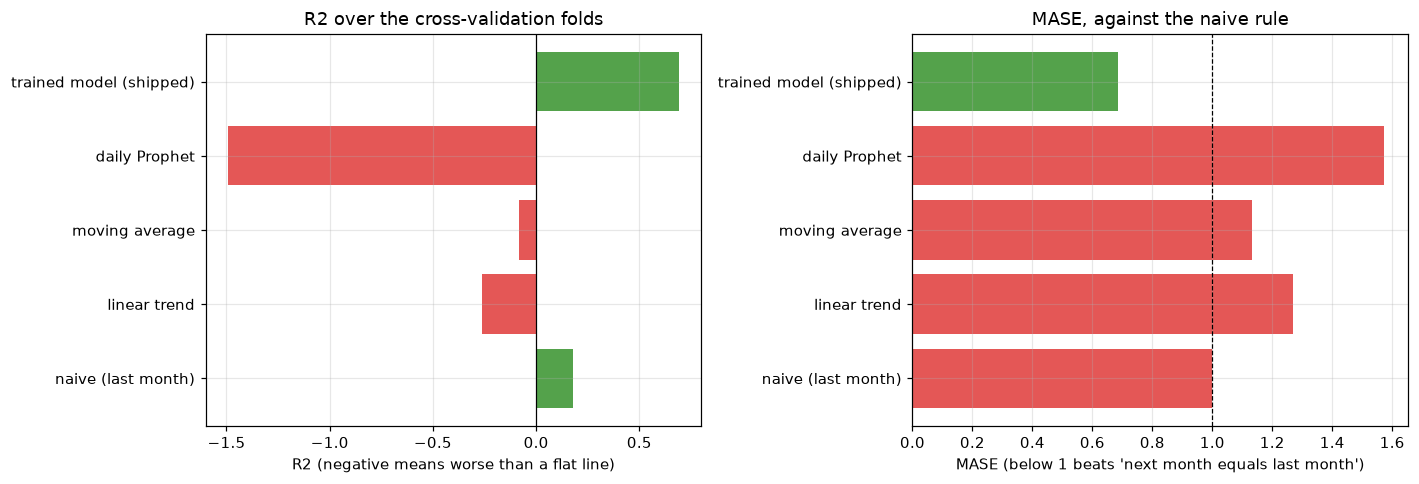

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

order_plot = list(full.index)[::-1]
colours = ["#54A24B" if v > 0 else "#E45756" for v in full.loc[order_plot, "R2"]]
ax[0].barh(order_plot, full.loc[order_plot, "R2"], color=colours)
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_title("R2 over the cross-validation folds")
ax[0].set_xlabel("R2 (negative means worse than a flat line)")

colours = ["#54A24B" if v < 1 else "#E45756" for v in full.loc[order_plot, "MASE"]]
ax[1].barh(order_plot, full.loc[order_plot, "MASE"], color=colours)
ax[1].axvline(1, color="k", ls="--", lw=0.8)
ax[1].set_title("MASE, against the naive rule")
ax[1].set_xlabel("MASE (below 1 beats 'next month equals last month')")

plt.tight_layout()
plt.show()

The three metrics agree, and two of them are harsher on the benchmarks than MAPE is.

The trained model is the only one with a positive R2 (0.69) and the only one with MASE
below 1 (0.69), meaning it is the only model here that beats simply carrying last month
forward — it does about a third less absolute error than the naive rule. Prophet's R2 of
-1.36 and MASE of 1.54 are the cold-start failures showing up in metrics that average
over all folds instead of splitting them: its accuracy on a mature business does not
survive contact with the months where it has little history. The moving average and the
linear trend also land above MASE 1.0, so neither is worth deploying over the naive rule.

The regime split printed above is the sharper version of the same point. R2 is 0.68 on
cold start and 0.70 on rich history, so the model explains essentially the same share of
the month-to-month variation whether or not the business has a year behind it.

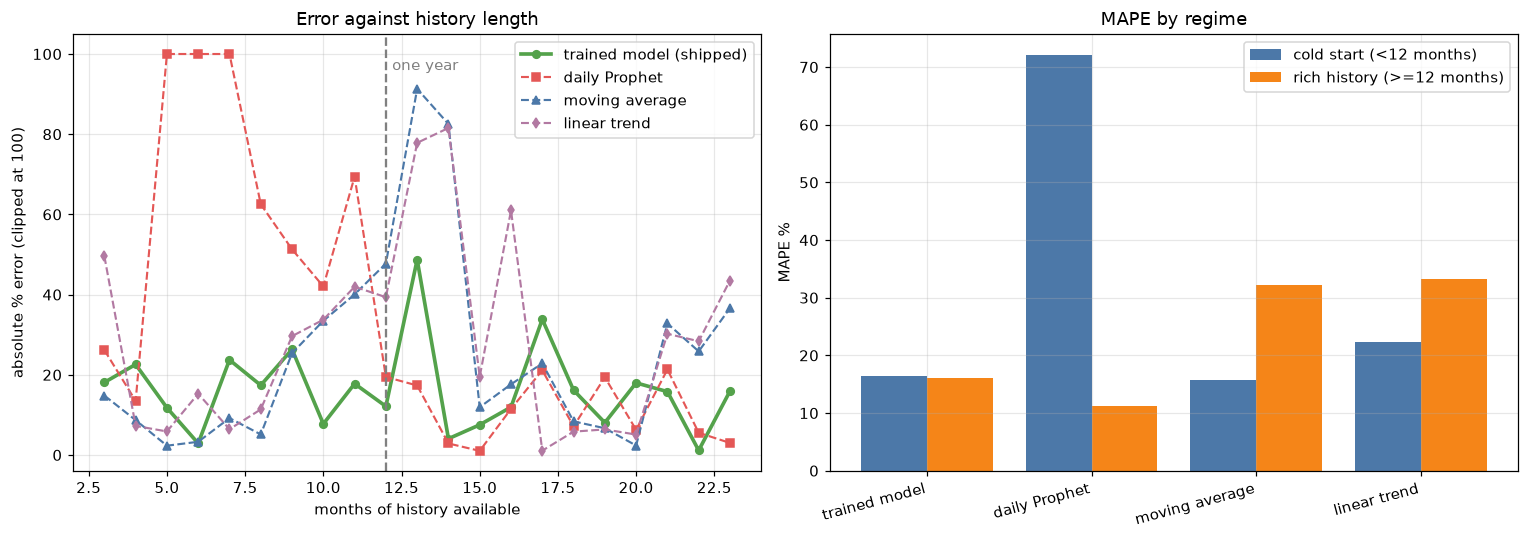

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

styles = {
    "trained model (shipped)": ("#54A24B", "o-", 2.4),
    "daily Prophet": ("#E45756", "s--", 1.4),
    "moving average": ("#4C78A8", "^--", 1.4),
    "linear trend": ("#B279A2", "d--", 1.4),
}

for name in ORDER:
    folds = results[name][0]
    colour, marker, width = styles[name]
    ax[0].plot(folds["nmonths"], folds["ape"].clip(upper=100), marker, color=colour, lw=width, label=name, ms=5)
ax[0].axvline(COLD_START_MONTHS, ls="--", color="grey")
ax[0].text(COLD_START_MONTHS + 0.2, 96, "one year", color="grey")
ax[0].set_xlabel("months of history available")
ax[0].set_ylabel("absolute % error (clipped at 100)")
ax[0].set_title("Error against history length")
ax[0].legend()

x = np.arange(len(comparison))
ax[1].bar(x - 0.2, comparison["MAPE cold <12mo"], 0.4, label="cold start (<12 months)", color="#4C78A8")
ax[1].bar(x + 0.2, comparison["MAPE rich >=12mo"], 0.4, label="rich history (>=12 months)", color="#F58518")
ax[1].set_xticks(x)
ax[1].set_xticklabels([n.replace(" (shipped)", "") for n in comparison.index], rotation=15, ha="right")
ax[1].set_ylabel("MAPE %")
ax[1].set_title("MAPE by regime")
ax[1].legend()

plt.tight_layout()
plt.show()

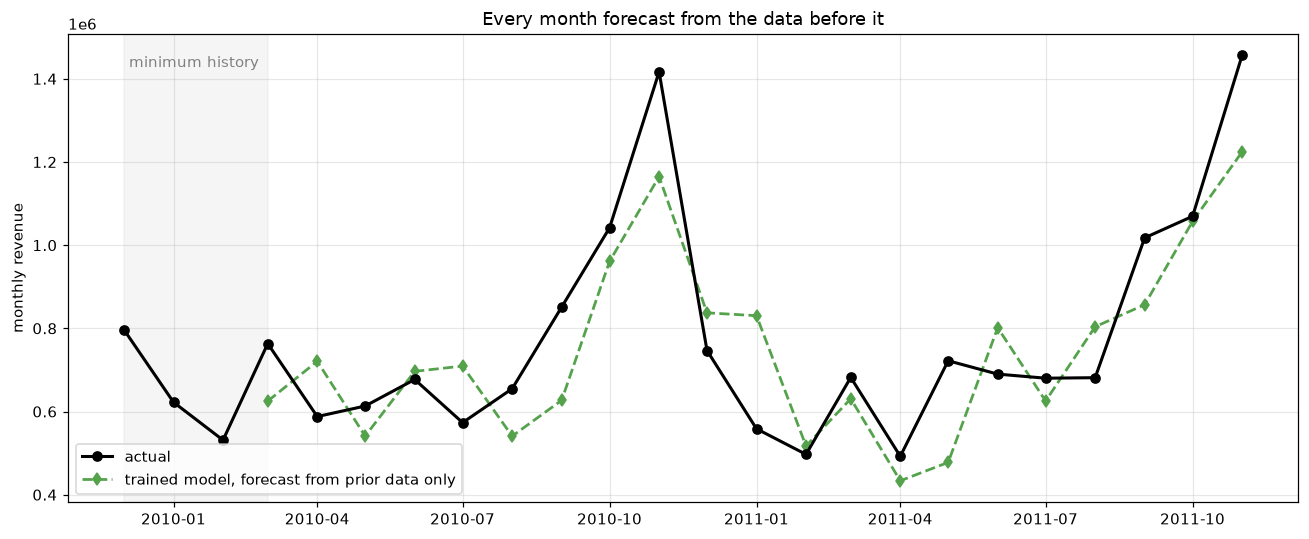

Worst three months:
  2011-01  actual      558,449  predicted      830,423  error  48.7%  (13 months of history)
  2011-05  actual      722,094  predicted      477,763  error  33.8%  (17 months of history)
  2010-09  actual      851,106  predicted      626,914  error  26.3%  (9 months of history)


In [26]:
folds = results["trained model (shipped)"][0]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, "k-o", lw=2, label="actual", zorder=3)
ax.plot(
    folds.index,
    folds["predicted"],
    "--d",
    color="#54A24B",
    lw=1.8,
    label="trained model, forecast from prior data only",
)
ax.axvspan(monthly.index[0], folds.index[0], color="grey", alpha=0.08)
ax.text(monthly.index[0], monthly.values.max(), " minimum history ", color="grey", va="top")
ax.set_ylabel("monthly revenue")
ax.set_title("Every month forecast from the data before it")
ax.legend()
plt.tight_layout()
plt.show()

worst = folds.nlargest(3, "ape")
print("Worst three months:")
for month, row in worst.iterrows():
    print(
        f"  {month:%Y-%m}  actual {row.actual:>12,.0f}  predicted {row.predicted:>12,.0f}  "
        f"error {row.ape:5.1f}%  ({int(row.nmonths)} months of history)"
    )

The trained model holds roughly the same accuracy in both regimes. Each benchmark is
accurate on one side and poor on the other.

The worst fold by a distance is the turn out of the Christmas peak into January 2011,
where monthly revenue falls by more than half in one step and the model carries too much
of December forward. The other two large misses are ordinary months that broke their own
pattern rather than a repeat of that failure. No model in this notebook handles the
January turn well, and with one January in the training data at that point there is not
much for any of them to learn from.

## 6.1 How much history the model needs

The backtest above starts at three months because that is the minimum the endpoint
accepts. Running it from one month shows why that floor is where it is.

In [27]:
short = expanding_backtest(series, trained_predict, min_history_months=1)

print("Error at each history length:")
for n in range(1, 7):
    fold = short[short.nmonths == n]
    if len(fold):
        print(
            f"  {n} month(s): predicted {fold['predicted'].iloc[0]:>12,.0f}   "
            f"actual {fold['actual'].iloc[0]:>12,.0f}   error {fold['ape'].iloc[0]:5.1f}%"
        )

print("\nGrouped:")
for lo, hi, label in [(1, 2, "1-2 months"), (3, 5, "3-5 months"), (6, 11, "6-11 months"), (12, 99, "12+ months")]:
    band = short[(short.nmonths >= lo) & (short.nmonths <= hi)]
    print(f"  {label:12} n={len(band):2}   MAPE {band['ape'].mean():5.1f}%")

Error at each history length:
  1 month(s): predicted            0   actual      622,480   error 100.0%
  2 month(s): predicted      706,117   actual      531,265   error  32.9%
  3 month(s): predicted      625,129   actual      763,247   error  18.1%
  4 month(s): predicted      720,705   actual      587,927   error  22.6%
  5 month(s): predicted      541,040   actual      613,271   error  11.8%
  6 month(s): predicted      696,629   actual      677,074   error   2.9%

Grouped:
  1-2 months   n= 2   MAPE  66.5%
  3-5 months   n= 3   MAPE  17.5%
  6-11 months  n= 6   MAPE  16.0%
  12+ months   n=12   MAPE  16.1%


One month of data clears the 28-day baseline window but leaves almost nothing to train
on, and the model returns a forecast near zero. Two months roughly doubles the
steady-state error. From three months the curve is flat at about 16 to 17%, and more
history does not improve it further.

Three complete months is therefore the minimum the endpoint accepts, and
`MIN_HISTORY_MONTHS` in `app/forecast/evaluation.py` is the single constant that sets
it for both the backtest and the served endpoint. Below that the API returns
`status: "unavailable"` with `reason: "insufficient_history"` rather than a number that
would be wrong by a factor of ten.

## 6.2 Benchmark 4: Azure AutoML

An Azure AutoML forecasting job was run on this dataset as an outside check on
everything above. It was given the preprocessed daily series with the same features this
notebook builds, told to forecast daily revenue at a 31-day horizon with five
cross-validations, and left to search for a day. Its best model, a voting ensemble of
five XGBoost learners and two random forests, reported **R2 0.869** against the 0.69
this notebook reports.

Two numbers that far apart usually mean the two are not measuring the same thing, so the
first job is to establish what AutoML's number is a score of. Its run publishes a
`forecast_table` artifact holding the actual predictions behind the metric, which is
enough to answer that exactly rather than by argument.

In [28]:
# Recorded from the AutoML run's forecast_table artifact. Job
# TrainUsingPreprocessedDailyRevenue, best run trainusingpreprocesseddailyrevenue_491:
# a VotingEnsemble of five XGBoost learners and two random forests.
AUTOML_FORECASTS = {
    "2011-11-05": [
        -669.7,
        33577.7,
        73367.6,
        65576.3,
        60529.7,
        67422.7,
        55629.5,
        -286.3,
        28875.1,
        95378.2,
        67079.7,
        62632.7,
        52381.3,
        49563.3,
        -0.8,
        34844.5,
        51587.5,
        53589.7,
        57271.6,
        52590.1,
        47900.5,
        452.5,
        27163.0,
        51410.8,
        67123.9,
        58659.5,
        54608.7,
        48417.5,
        430.2,
        34431.6,
        49798.1,
    ],
    "2011-11-06": [
        33746.4,
        71571.6,
        65379.1,
        60618.6,
        67108.0,
        55064.2,
        -65.5,
        28096.6,
        93254.7,
        67351.4,
        63174.8,
        52274.6,
        48941.4,
        25.2,
        35094.3,
        50599.1,
        52425.8,
        56905.1,
        52075.7,
        47356.4,
        202.3,
        26365.0,
        50175.1,
        66107.5,
        57754.4,
        53467.0,
        46976.1,
        1025.4,
        34620.5,
        49484.9,
        48035.2,
    ],
    "2011-11-07": [
        75057.6,
        64000.7,
        60999.0,
        66515.8,
        52453.1,
        399.5,
        29521.9,
        96289.8,
        62926.6,
        61985.9,
        52385.5,
        48689.6,
        472.9,
        37460.3,
        50026.8,
        51766.6,
        54932.4,
        52644.2,
        50201.1,
        41.3,
        28159.7,
        54055.8,
        66653.7,
        56918.1,
        53958.3,
        47305.6,
        814.0,
        36954.3,
        49180.6,
        49762.7,
        46248.3,
    ],
    "2011-11-08": [
        66947.8,
        63703.7,
        67151.6,
        51950.0,
        50.9,
        30321.1,
        94562.9,
        70330.6,
        62411.1,
        53763.3,
        49625.4,
        104.9,
        36268.9,
        52621.7,
        52967.6,
        57908.0,
        53689.8,
        51745.3,
        5.3,
        27636.6,
        56316.0,
        67110.1,
        59031.7,
        54113.6,
        47163.2,
        760.6,
        38846.4,
        49959.6,
        49157.3,
        47271.9,
        43901.3,
    ],
    "2011-11-09": [
        60176.5,
        67545.0,
        50481.9,
        62.5,
        30314.0,
        94249.4,
        70366.2,
        61966.7,
        54249.0,
        47804.0,
        171.6,
        35447.3,
        49751.0,
        51721.7,
        56715.4,
        54969.6,
        51180.5,
        115.0,
        26578.4,
        56561.7,
        67749.7,
        61309.9,
        55428.6,
        48301.9,
        556.0,
        37350.4,
        49780.0,
        48658.7,
        46435.7,
        44923.3,
        45505.4,
    ],
}

AUTOML_REPORTED = {
    "r2_score": 0.8693566,
    "explained_variance": 0.8793790,
    "mean_absolute_error": 6018.791,
    "mean_absolute_percentage_error": 12.89375,
    "root_mean_squared_error": 9018.470,
    "normalized_root_mean_squared_error": 0.06714688,
}
print("AutoML reported, on its own evaluation:")
for name, value in AUTOML_REPORTED.items():
    print(f"  {name:38} {value:>12,.5f}")

AutoML reported, on its own evaluation:
  r2_score                                    0.86936
  explained_variance                          0.87938
  mean_absolute_error                     6,018.79100
  mean_absolute_percentage_error             12.89375
  root_mean_squared_error                 9,018.47000
  normalized_root_mean_squared_error          0.06715


### What those five folds actually cover

Each entry in the table is one cross-validation fold: an origin, and the 31 days
forecast from it. Lining the origins up is the whole story.

In [29]:
def daily_from(history, days):
    """Our shipped model asked for a run of days rather than a calendar month."""
    model = TrainedRevenueModel().fit(history, country=COUNTRY)
    scale = float(history.iloc[-BASELINE_WINDOW:].mean())
    features = build_features(days, history, scale, COUNTRY, detect_closed_days(history))
    return np.clip(model.model.predict(features), 0, None) * scale


def r2_of(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return 1 - float(((actual - predicted) ** 2).sum()) / float(((actual - actual.mean()) ** 2).sum())


fold_rows, every_day = [], {}
pooled = {"actual": [], "automl": [], "ours": []}
for start, automl_pred in AUTOML_FORECASTS.items():
    days = pd.date_range(start, periods=len(automl_pred), freq="D")
    actual = series.reindex(days)
    history = series.loc[: days[0] - pd.Timedelta(days=1)]
    our_pred = daily_from(history, days)

    fold_rows.append(
        {
            "history ends": f"{history.index[-1]:%Y-%m-%d}",
            "months of history": len(monthly_totals(history)),
            "forecast window": f"{days[0]:%Y-%m-%d} to {days[-1]:%Y-%m-%d}",
            "AutoML R2": round(r2_of(actual.values, automl_pred), 3),
            "our R2": round(r2_of(actual.values, our_pred), 3),
        }
    )
    pooled["actual"] += list(actual.values)
    pooled["automl"] += list(automl_pred)
    pooled["ours"] += list(our_pred)
    for day in days:
        every_day.setdefault(day, 0)
        every_day[day] += 1

folds_frame = pd.DataFrame(fold_rows)
print(folds_frame.to_string(index=False))

covered = sorted(every_day)
print(f"\npooled over the five folds, {len(pooled['actual'])} scored points")
print(
    f"  AutoML daily R2 {r2_of(pooled['actual'], pooled['automl']):.3f}"
    f"   (the leaderboard reports {AUTOML_REPORTED['r2_score']:.3f})"
)
print(f"  ours   daily R2 {r2_of(pooled['actual'], pooled['ours']):.3f}")
print(
    f"\ndistinct calendar days covered: {len(covered)} "
    f"({covered[0]:%Y-%m-%d} to {covered[-1]:%Y-%m-%d}), "
    f"out of {len(series)} in the series"
)
print(f"each covered day is scored {np.mean(list(every_day.values())):.1f} times on average")
for month in ["2011-11", "2011-12"]:
    end = pd.Timestamp(month + "-01") + pd.offsets.MonthEnd(0)
    hit = sum(1 for d in covered if f"{d:%Y-%m}" == month)
    print(f"  {month}: {hit} of {end.day} days covered")

history ends  months of history          forecast window  AutoML R2  our R2
  2011-11-04                 23 2011-11-05 to 2011-12-05      0.931   0.602
  2011-11-05                 23 2011-11-06 to 2011-12-06      0.913   0.587
  2011-11-06                 23 2011-11-07 to 2011-12-07      0.878   0.515
  2011-11-07                 23 2011-11-08 to 2011-12-08      0.813   0.548
  2011-11-08                 23 2011-11-09 to 2011-12-09      0.812   0.545

pooled over the five folds, 155 scored points
  AutoML daily R2 0.869   (the leaderboard reports 0.869)
  ours   daily R2 0.561

distinct calendar days covered: 35 (2011-11-05 to 2011-12-09), out of 739 in the series
each covered day is scored 4.4 times on average
  2011-11: 26 of 30 days covered
  2011-12: 9 of 31 days covered


The five folds step forward **one day at a time**, so they forecast very nearly the same
month five times over. Between them they cover 35 distinct days, 27 of which appear in
every fold, out of the 739 in the series. Every one of those days falls in the November
to December run-up, and every fold has close to two full years of history behind it.

Two consequences follow, and they point in opposite directions, so both belong here.

**Against the comparison.** AutoML's 0.869 is a score on 35 days of one peak season with
a fully trained model. This notebook's 0.69 is a score on 21 non-overlapping months,
nine of which are cold start. It also scores a different quantity: daily revenue against
the mean of a 35-day window, not a monthly total against the mean of two years. Neither
number can be read as the other, and no complete calendar month is covered by AutoML's
folds at all, so its output cannot simply be re-scored on this notebook's task.

**For it.** On its own task, on its own window, AutoML is better than the shipped model
and it is not close. Reproducing 0.869 from its own predictions confirms the table is
read correctly, and the same arithmetic gives our model 0.56.

In [30]:
nonzero = [i for i, v in enumerate(pooled["actual"]) if v > 0]


def daily_mape(predicted):
    return float(np.mean([abs(predicted[i] - pooled["actual"][i]) / pooled["actual"][i] for i in nonzero]) * 100)


head_to_head = pd.DataFrame(
    [
        {
            "scored on": "daily revenue, AutoML's 5 folds",
            "AutoML": round(r2_of(pooled["actual"], pooled["automl"]), 3),
            "ours": round(r2_of(pooled["actual"], pooled["ours"]), 3),
            "metric": "R2",
        },
        {
            "scored on": "daily revenue, AutoML's 5 folds",
            "AutoML": round(daily_mape(pooled["automl"]), 1),
            "ours": round(daily_mape(pooled["ours"]), 1),
            "metric": "MAPE % (zero days excluded)",
        },
    ]
).set_index("scored on")
print("Head to head on AutoML's task and window:\n")
print(head_to_head.to_string())

totals = []
for start, automl_pred in AUTOML_FORECASTS.items():
    days = pd.date_range(start, periods=len(automl_pred), freq="D")
    actual = float(series.reindex(days).sum())
    history = series.loc[: days[0] - pd.Timedelta(days=1)]
    ours_total = float(daily_from(history, days).sum())
    automl_total = float(np.sum(automl_pred))
    totals.append(
        {
            "window": f"{days[0]:%m-%d} to {days[-1]:%m-%d}",
            "actual total": round(actual),
            "AutoML error %": round(abs(automl_total - actual) / actual * 100, 1),
            "our error %": round(abs(ours_total - actual) / actual * 100, 1),
        }
    )
totals_frame = pd.DataFrame(totals)
print("\n\nAnd on the aggregate this product actually ships, the 31-day total:\n")
print(totals_frame.to_string(index=False))
print(
    f"\nmean absolute error on the total:  "
    f"AutoML {totals_frame['AutoML error %'].mean():.1f}%   "
    f"ours {totals_frame['our error %'].mean():.1f}%"
)

Head to head on AutoML's task and window:

                                 AutoML    ours                       metric
scored on                                                                   
daily revenue, AutoML's 5 folds   0.869   0.561                           R2
daily revenue, AutoML's 5 folds  12.900  20.900  MAPE % (zero days excluded)


And on the aggregate this product actually ships, the 31-day total:

        window  actual total  AutoML error %  our error %
11-05 to 12-05       1450274             3.4         20.3
11-06 to 12-06       1504383             4.6         20.0
11-07 to 12-07       1536856             5.1         21.2
11-08 to 12-08       1548326             5.9         19.1
11-09 to 12-09       1523952             6.4         19.8

mean absolute error on the total:  AutoML 5.1%   ours 20.1%


That is the honest result and it is worth stating plainly: **on a mature business over a
peak month, the AutoML ensemble calls both the individual days and the period total
better than the model this notebook ships.** Ours under-forecasts the run-up on all five
windows by around 20%, which is the same failure section 6 already found in the December
and January folds.

So the next question is where the difference comes from, because the answer decides
whether it is something to adopt or something the product's constraints forbid.

In [31]:
def with_momentum(history, days):
    """The shipped feature set plus the momentum column section 5.4 rejected."""
    closed_days = detect_closed_days(history)
    baseline = history.shift(1).rolling(BASELINE_WINDOW).mean().to_numpy()
    columns = ["weekday_ratio", "momentum"]  # the shipped set, plus momentum
    train = feature_frame(history.index, history, baseline, closed_days, columns)
    target = history.to_numpy() / baseline
    usable = np.isfinite(baseline) & (baseline > 0) & np.isfinite(target)
    model = lgb.LGBMRegressor(**DEFAULT_PARAMS).fit(train[usable], target[usable])
    scale = float(history.iloc[-BASELINE_WINDOW:].mean())
    future = feature_frame(days, history, scale, closed_days, columns)
    return np.clip(model.predict(future), 0, None) * scale


rows = []
for start, automl_pred in AUTOML_FORECASTS.items():
    days = pd.date_range(start, periods=len(automl_pred), freq="D")
    actual = float(series.reindex(days).sum())
    history = series.loc[: days[0] - pd.Timedelta(days=1)]
    err = lambda total: round(abs(total - actual) / actual * 100, 1)
    rows.append(
        {
            "window": f"{days[0]:%m-%d} to {days[-1]:%m-%d}",
            "shipped": err(float(daily_from(history, days).sum())),
            "+ momentum": err(float(with_momentum(history, days).sum())),
            "AutoML": err(float(np.sum(automl_pred))),
        }
    )
momentum_frame = pd.DataFrame(rows)
print("Error on the 31-day total, with the rejected momentum feature added back:\n")
print(momentum_frame.to_string(index=False))
print(
    "\nmean:  "
    + "   ".join(f"{name} {momentum_frame[name].mean():.1f}%" for name in ["shipped", "+ momentum", "AutoML"])
)

Error on the 31-day total, with the rejected momentum feature added back:

        window  shipped  + momentum  AutoML
11-05 to 12-05     20.3        12.5     3.4
11-06 to 12-06     20.0        15.9     4.6
11-07 to 12-07     21.2        15.4     5.1
11-08 to 12-08     19.1        11.0     5.9
11-09 to 12-09     19.8         9.7     6.4

mean:  shipped 20.1%   + momentum 12.9%   AutoML 5.1%


Adding momentum closes roughly a third of the gap, from 20% to 13% against AutoML's 5%.
That is a real part of the explanation and not the whole of it.

It is also a result section 5.4 already produced from the other direction. Momentum was
the strongest feature in that table on rich history, 14.0% against 16.6%, and the worst
on cold start, 19.9% against 17.0%. AutoML's advantage here is measured on a business
with 23 months of history, which is precisely the regime where momentum wins and
precisely the regime most of this product's users are not in. Two independent searches
found the same thing: recent direction is worth a lot once a business is mature.

The rest of the gap is the part the deployment constraint forbids. AutoML fits this one
series in absolute pounds and generates its own lagged copies of the target, so it is a
specialist in one shop's recent behaviour. That is the same disqualification Prophet
carries from section 4: nothing is trained once and shared, there is no artifact to save,
and a business in its first months has nothing for it to fit.

The last check is the one that settles whether the algorithms themselves are better, as
opposed to the framing they were given. Below, the configurations from the top of
AutoML's leaderboard are trained on this notebook's target, with this notebook's
features, and scored on this notebook's cross-validation.

In [32]:
try:
    from xgboost import XGBRegressor

    HAVE_XGBOOST = True
except ImportError:  # optional, see requirements.txt
    HAVE_XGBOOST = False
    print("xgboost not installed - showing the random forest rows only\n")

from sklearn.ensemble import RandomForestRegressor


def scored_as_ours(build_estimator):
    def predict(history):
        closed_days = detect_closed_days(history)
        baseline = history.shift(1).rolling(BASELINE_WINDOW).mean().to_numpy()
        X = build_features(history.index, history, baseline, COUNTRY, closed_days)
        y = history.to_numpy() / baseline
        usable = np.isfinite(baseline) & (baseline > 0) & np.isfinite(y)
        estimator = build_estimator().fit(X[usable], y[usable])
        scale = float(history.iloc[-BASELINE_WINDOW:].mean())
        start = (history.index.max() + pd.offsets.MonthBegin(1)).normalize()
        days = pd.date_range(start, start + pd.offsets.MonthEnd(0), freq="D")
        future = build_features(days, history, scale, COUNTRY, closed_days)
        return float((np.clip(estimator.predict(future), 0, None) * scale).sum())

    return predict


# Hyperparameters as reported on AutoML's Job B leaderboard.
LEADERBOARD = {"LightGBM (this notebook)": lambda: lgb.LGBMRegressor(**DEFAULT_PARAMS)}
if HAVE_XGBOOST:
    LEADERBOARD["XGBoost (leaderboard 2nd)"] = lambda: XGBRegressor(
        booster="gbtree", colsample_bytree=0.9, eta=0.2, max_depth=8, n_estimators=100, random_state=0, verbosity=0
    )
    LEADERBOARD["XGBoost (leaderboard 4th)"] = lambda: XGBRegressor(
        booster="gbtree",
        colsample_bytree=0.9,
        eta=0.1,
        gamma=10,
        max_depth=9,
        n_estimators=100,
        random_state=0,
        verbosity=0,
    )
LEADERBOARD["RandomForest (leaderboard 6th)"] = lambda: RandomForestRegressor(
    criterion="squared_error",
    max_features=0.7,
    min_samples_leaf=0.0023646822772690063,
    min_samples_split=0.015297321160913582,
    n_estimators=100,
    random_state=0,
)

reverse_folds = {name: expanding_backtest(series, scored_as_ours(build)) for name, build in LEADERBOARD.items()}

ensemble = next(iter(reverse_folds.values())).copy()
ensemble["predicted"] = sum(f["predicted"] for f in reverse_folds.values()) / len(reverse_folds)
ensemble["ape"] = (ensemble["predicted"] - ensemble["actual"]).abs() / ensemble["actual"] * 100
reverse_folds["voting ensemble of the above"] = ensemble
reverse_folds["naive (last month)"] = demo

reverse = pd.DataFrame({name: metrics(f) for name, f in reverse_folds.items()}).T
reverse = reverse[["MAPE %", "R2", "MASE"]].sort_values("MAPE %")
reverse.round({"MAPE %": 1, "R2": 3, "MASE": 3})

,MAPE %,R2,MASE
LightGBM (this notebook),16.3,0.691,0.687
voting ensemble of the above,21.7,0.351,0.934
XGBoost (leaderboard 4th),21.9,0.121,0.948
naive (last month),22.7,0.180,1.000
RandomForest (leaderboard 6th),25.1,0.127,1.096
XGBoost (leaderboard 2nd),28.6,-0.127,1.218


Asked this notebook's question, none of them gets clear of the naive "next month equals
last month" rule. The best lands at 21.8% MAPE and MASE 0.94 against the naive rule's
22.7% and 1.00 — an improvement too small to deploy for — and two are worse than doing
nothing at all. The shipped model's 16.3% and 0.69 are a different order of result.

So the algorithms are not what produced 0.869; the framing was — a daily target, a
mature series, a peak month, and lagged copies of the target itself.

## 6.3 Serving the AutoML model

AutoML wins the only head-to-head that can be run, so its model is the one the
application serves. This section records how that works and what is still unmeasured.

### Serving one business's model to any business

The endpoint forecasts revenue in pounds, at the level it was trained on. Scaling a
business's history so its trailing 28-day average matches that level, asking for a
forecast, then dividing the answer back is exact for a difference in size. It is the
normalisation from section 5.1, applied around the model instead of built into its
target. The application does this on every request:

1. build the business's daily series
2. `k` = AutoML's training baseline / the business's trailing 28-day average
3. multiply the series, and `lag364`, by `k`
4. ask the endpoint for the next month's days
5. sum them, divide by `k`

Step 3 has to include `lag364`, which the data asset carries as a raw amount rather than
a ratio.

The model trained in section 9 needs no wrapper, because its ratio target makes it
scale-free by construction:

In [33]:
original = TrainedRevenueModel().fit(series, country=COUNTRY)
reference = original.forecast_next_month(series, country=COUNTRY).predicted_revenue
print(f"forecast from the series as given: {reference:,.2f}\n")
for factor in [0.02, 0.2, 5.0, 50.0]:
    resized = series * factor
    model = TrainedRevenueModel().fit(resized, country=COUNTRY)
    got = model.forecast_next_month(resized, country=COUNTRY).predicted_revenue
    print(
        f"  business x{factor:<5} forecast {got:>16,.2f}   divided back {got / factor:>14,.2f}"
        f"   difference {abs(got / factor - reference) / reference:.1e}"
    )

forecast from the series as given: 1,473,461.78

  business x0.02  forecast        29,469.24   divided back   1,473,461.78   difference 1.6e-16
  business x0.2   forecast       294,692.36   divided back   1,473,461.78   difference 3.2e-16
  business x5.0   forecast     7,367,308.92   divided back   1,473,461.78   difference 1.6e-16
  business x50.0  forecast    73,673,089.19   divided back   1,473,461.78   difference 1.6e-16


Identical to floating-point precision at every size, so the same wrapper applied to the
endpoint is exact too.

### Why it is called over HTTP rather than loaded

The AutoML model cannot run inside this application's process. It was trained under a
different runtime:

| | AutoML model | This application |
| --- | --- | --- |
| Python | 3.10.19 | 3.12 |
| numpy | 1.23.5 | 2.4.6 |
| pandas | 1.5.3 | 2.2.2 |
| scikit-learn | 1.5.1 | 1.7.2 |
| xgboost | <= 1.5.2 | 3.2.0 |

pandas 1.5.3 and numpy 1.23.5 have no builds for Python 3.12, so this is a different
interpreter rather than a set of versions to downgrade. The model is deployed to an Azure
managed online endpoint, which gives it its own container, and the application calls it
over HTTPS.

### What is not known about it

It trained on all 739 days, so it cannot be scored on this notebook's cross-validation:
every fold would be a month it has already seen. Its accuracy on next-month totals is
unmeasured, and the only numbers behind it are the 35 days in section 6.2.

The model trained in section 9 stays in the repository. The application falls back to it
when the endpoint is unreachable, and the response records which of the two produced the
forecast.

### What to take from this

- AutoML's 0.869 and this notebook's 0.69 are not comparable, and the leaderboard number
  should not be quoted as though they were. Different target, different granularity,
  35 days against 21 months, no cold start against nine folds of it.
- On the task AutoML was set, its model is genuinely better than this one, and that is
  worth knowing rather than explaining away.
- Its advantage was measured on a business with 23 months of history, and largely comes
  from the feature section 5.4 found best on rich history and worst on cold start. Most
  users of this product arrive with months rather than years, so its lead on the folds in
  6.2 is not evidence of a lead on a new business.
- The gap is a good argument for the step section 10 already names: train the same
  architecture across many businesses at once. Pooling is what would let a
  momentum-style signal be learned safely, because it could be estimated across
  businesses instead of from one shop's noisy fortnight.

---
# 7. What the model learned

A gradient-boosted tree ensemble is not readable directly. SHAP attributes each
prediction back to the features that produced it, which checks the design in section 5
against the fitted model and is the route to explaining a forecast to a user later.

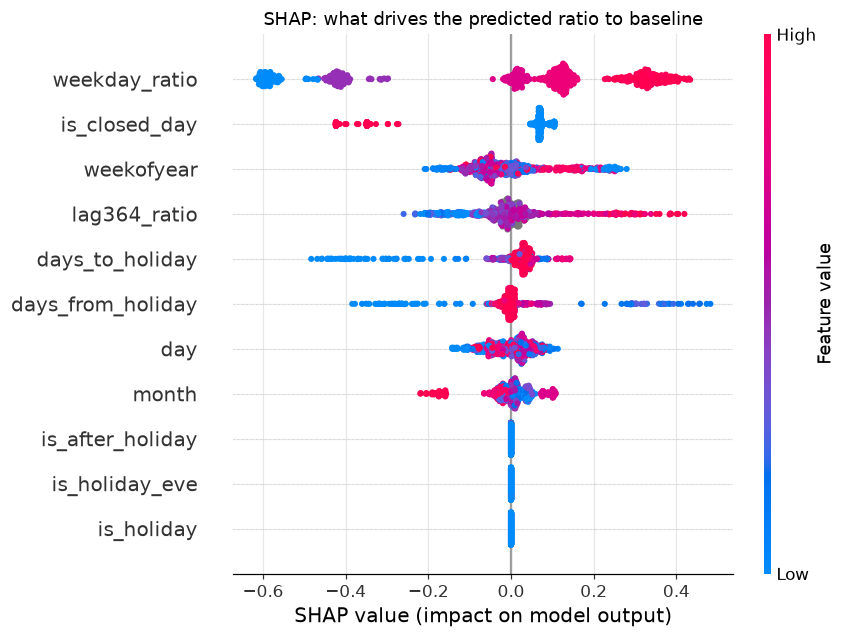

,mean |SHAP|,split gain
weekday_ratio,0.2738,1240.6
is_closed_day,0.1172,472.9
weekofyear,0.0763,187.0
lag364_ratio,0.0645,318.3
days_to_holiday,0.0568,179.6
days_from_holiday,0.0505,162.2
day,0.0402,60.6
month,0.0361,50.9
is_holiday,0.0000,0.0
is_holiday_eve,0.0000,0.0


In [34]:
import shap

final_model = TrainedRevenueModel().fit(series, country=COUNTRY)

baseline_column = series.shift(1).rolling(BASELINE_WINDOW).mean()
X_all = build_features(series.index, series, baseline_column.to_numpy(), COUNTRY, detect_closed_days(series))
usable = np.isfinite(baseline_column.to_numpy()) & (baseline_column.to_numpy() > 0)
X_explain = X_all[usable]

shap_values = shap.TreeExplainer(final_model.model).shap_values(X_explain)
shap.summary_plot(shap_values, X_explain, show=False)
plt.title("SHAP: what drives the predicted ratio to baseline")
plt.tight_layout()
plt.show()

influence = pd.DataFrame(
    {
        "mean |SHAP|": np.abs(shap_values).mean(axis=0),
        "split gain": final_model.model.booster_.feature_importance("gain"),
    },
    index=X_explain.columns,
).sort_values("mean |SHAP|", ascending=False)
influence.round({"mean |SHAP|": 4, "split gain": 1})

The two features that describe how this particular store trades are the two the model
leans on hardest, and they are ranked in the order the design predicted: `weekday_ratio`
first by a wide margin, `is_closed_day` behind it. Both are read from the store's own
history rather than from an assumed weekend, which is what the transfer argument in
section 8 rests on. `lag364_ratio` and `weekofyear` carry the yearly shape, and the two
holiday *distances* carry the run-up and the recovery around a public holiday.

`is_holiday`, `is_holiday_eve` and `is_after_holiday` score exactly zero. The model never
splits on them once, and that is not a quirk of this dataset: `days_to_holiday == 0` is
the same statement as `is_holiday`, `days_to_holiday == 1` is the same as
`is_holiday_eve`, and `days_from_holiday == 1` is the same as `is_after_holiday`. The
three binaries are structurally redundant against the two distances on any calendar, so
the ensemble takes the distance columns and never looks at them again. They are
harmless — the predictions are identical with or without them — but they are three of
the eleven columns the feature set carries, and dropping them is a clean simplification
whenever this model is next touched.

Nothing in the plot is specific to the UK.

---
# 8. Transfer to another region

The claim to test is that this model can be given a business elsewhere without
retraining.

The model never sees a country. It sees a rest-day flag derived from the series it is
given and holiday features derived from whichever calendar is passed in. Changing the
calendar changes the output of the same trained booster.

Below, one trained model forecasts the same series twice, once under the UK calendar
and once under the Palestinian one.

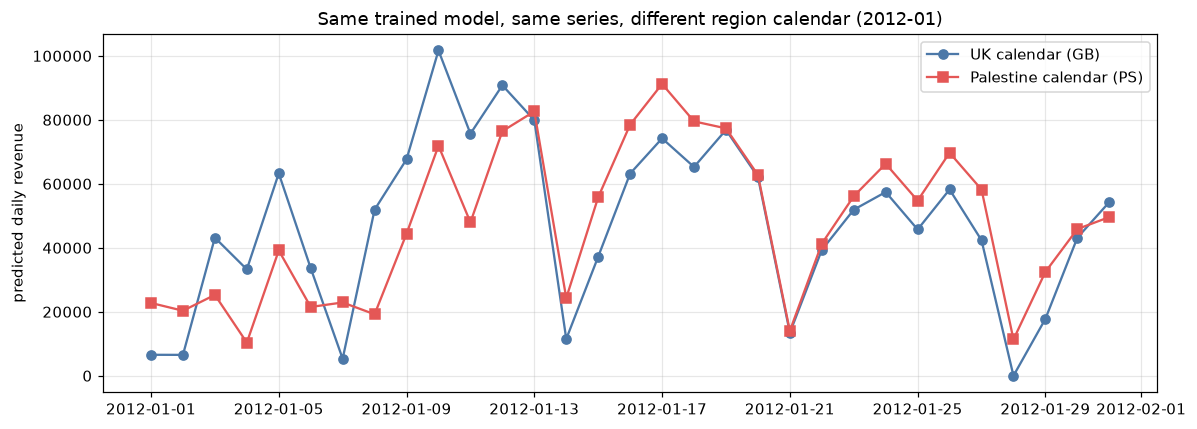

Next-month total   UK: 1,473,462   Palestine: 1,474,028
Difference: 0.0%


In [35]:
uk = final_model.forecast_next_month(series, country="GB")
ps = final_model.forecast_next_month(series, country="PS")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(uk.daily.index, uk.daily.values, "-o", color="#4C78A8", label="UK calendar (GB)")
ax.plot(ps.daily.index, ps.daily.values, "-s", color="#E45756", label="Palestine calendar (PS)")
ax.set_ylabel("predicted daily revenue")
ax.set_title(f"Same trained model, same series, different region calendar ({uk.target_month})")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Next-month total   UK: {uk.predicted_revenue:,.0f}   Palestine: {ps.predicted_revenue:,.0f}")
print(f"Difference: {abs(uk.predicted_revenue - ps.predicted_revenue) / uk.predicted_revenue:.1%}")

In [36]:
# The rest day is read from the data, not assumed. Shift this store's trading pattern
# back a day so it closes Friday instead of Saturday, and the same model follows it.
shifted = series.copy()
shifted.index = shifted.index - pd.Timedelta(days=1)

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("original series rest day:", sorted(detect_closed_days(series)), "(5 = Saturday)")
print("shifted  series rest day:", sorted(detect_closed_days(shifted)), "(4 = Friday)")

shifted_forecast = final_model.forecast_next_month(shifted, country="PS")
by_weekday = shifted_forecast.daily.groupby(shifted_forecast.daily.index.dayofweek).mean()
print("\nPredicted average revenue by weekday for the shifted store:")
for dow, value in by_weekday.items():
    print(f"  {WEEKDAYS[dow]}: {value:>10,.0f}")

original series rest day: [5] (5 = Saturday)
shifted  series rest day: [4] (4 = Friday)

Predicted average revenue by weekday for the shifted store:
  Mon:     62,588
  Tue:     45,792
  Wed:     66,724
  Thu:     47,427
  Fri:     13,402
  Sat:     42,355
  Sun:     56,872


The model puts the near-zero day where the data says the shop is closed and reacts to
whichever holidays it is given.

This shows the mechanism, not the accuracy. The inputs are region-generic and the model
responds correctly to a new calendar, but the magnitude of an Eid effect was never
learned, because no Eid appears in UK training data. Measuring that needs training
across businesses in several regions, which is the next step in section 10.

---
# 9. Training the served artifact

The model is trained on the full history and written to the path
`app/forecast/service.py` resolves by default, so the artifact saved here is the one
the endpoint loads. It is then reloaded from disk and run through the service function,
which confirms the model in this notebook and the model in the running application are
the same.

`scripts/train_revenue_model.py` performs the same training as a single command for a
deployment.

In [37]:
from app.forecast.service import DEFAULT_MODEL_PATH

DEFAULT_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
final_model.save(str(DEFAULT_MODEL_PATH))

size_kb = DEFAULT_MODEL_PATH.stat().st_size / 1024
print(f"saved {DEFAULT_MODEL_PATH}  ({size_kb:,.0f} KB)")
print(f"trained on {len(series)} days, {series.index.min():%Y-%m-%d} to {series.index.max():%Y-%m-%d}")
print(f"parameters: {DEFAULT_PARAMS}")

saved /Users/maen/ASAL-AI26/Project B/backend/models/revenue_model.joblib  (486 KB)
trained on 739 days, 2009-12-01 to 2011-12-09
parameters: {'n_estimators': 1200, 'learning_rate': 0.05, 'num_leaves': 3, 'min_child_samples': 40, 'subsample': 0.9, 'colsample_bytree': 0.9, 'random_state': 0, 'verbose': -1}


In [38]:
from app.forecast.service import forecast_from_dataframe

served = forecast_from_dataframe(std[["transaction_date", "quantity", "unit_price"]], region="europe")
print("The response the API would return for this business:\n")
for key in ["status", "target_month", "predicted_revenue", "model", "reason"]:
    print(f"  {key:18} {served.to_dict()[key]}")
print(f"  {'history points':18} {len(served.history)}")

reloaded = TrainedRevenueModel.load(str(DEFAULT_MODEL_PATH))
direct = reloaded.forecast_next_month(series, country="GB").predicted_revenue
print(f"\nreloaded artifact forecast: {direct:,.2f}")
print(f"served response forecast:   {served.predicted_revenue:,.2f}")
print("identical:", abs(direct - served.predicted_revenue) < 1e-6)

The response the API would return for this business:

  status             available
  target_month       2012-01
  predicted_revenue  1473461.7837025442
  model              trained_revenue
  reason             None
  history points     24

reloaded artifact forecast: 1,473,461.78
served response forecast:   1,473,461.78
identical: True


---
# 10. Results and limitations

In [39]:
summary = comparison.copy()
summary["steady across both?"] = [
    "yes" if abs(row["MAPE cold <12mo"] - row["MAPE rich >=12mo"]) < 5 else "no" for _, row in summary.iterrows()
]
summary

,MAPE cold <12mo,MAPE rich >=12mo,MAPE overall,steady across both?
model,,,,
trained model (shipped),16.5,16.1,16.3,yes
daily Prophet,72.1,11.3,37.4,no
moving average,15.8,32.2,25.2,no
linear trend,22.3,33.3,28.6,no


## Conclusion

One LightGBM model, trained once, applying to every business. It is what this notebook
set out to build, and the application serves it whenever the AutoML endpoint from
section 6.3 cannot answer.

- It is the only model measured here that is steady across both regimes. Each benchmark
  is accurate at one end of the history axis and poor at the other.
- It is the only one that beats the naive rule on the metrics that average over all
  folds: MASE 0.69 against 1.13 and above for every benchmark, and the only positive
  R2 at 0.69. MAPE selected both the feature set and the hyperparameters, and the other
  metrics agree with the result.
- It is the only one deployable as a single shared artifact. Prophet and the simple
  models are computed per business per request and have nothing to save.
- It is transfer-ready by construction: a scale-free target, a rest day and a weekday
  profile read from the store's own data, and holiday features that name no holiday.

Prophet is more accurate on this business once it has a full year. That trade is
deliberate: the product's users are mostly new businesses, a per-request refit is not
the required architecture, and Prophet has no answer for a business's first months. Its
negative R2 and MASE of 1.54 over the full cross-validation are what that costs when the
whole life of a business is scored rather than its mature months alone.

## Limitations

- Every number here comes from a single UK retailer. Cold start and rich history are
  two slices of the same 24 months, not independent samples. The results are
  directional.
- Transfer is demonstrated as a mechanism, not measured as accuracy. Section 8 shows the
  model responding correctly to another region's calendar; it does not establish that
  the size of an Eid effect is right, and it cannot from UK data.
- Neither the large single-day spikes nor the administrative rows are removed. That is
  defensible for a monthly total and should be revisited for anything finer.
- The model sees nothing outside the sales file. A promotion, a stockout or a price
  change is invisible to it and appears as error.
- Every figure in this section describes the model built here, not the AutoML endpoint
  the application prefers. That one's accuracy on next-month totals is unmeasured, for
  the reason given in section 6.3.

## Next step

Train the same architecture across many businesses' series at once. The features are
already scale-free and region-generic, which is what makes a pooled model possible, and
pooling would both raise accuracy and turn the transfer claim into a measurement.